# Лабораторная работа: Генеративные модели классификации (LDA и Naive Bayes)

## Общая цель работы
Изучить генеративный подход к классификации на примере двух моделей: **Линейный дискриминантный анализ (LDA)** и **Наивный байесовский классификатор (NB)**. Вы не просто реализуете алгоритмы, а исследуете, как предположения о структуре данных (ковариация, независимость признаков) влияют на разделяющую поверхность и качество классификации.

---

## Теоретическое введение (обязательно к прочтению)

### Генеративный vs дискриминативный подход
- **Дискриминативные модели** (логистическая регрессия, SVM) моделируют границу между классами напрямую: $ p(y|x) $.
- **Генеративные модели** моделируют совместное распределение $ p(x, y) = p(x|y) \cdot p(y) $, а затем через теорему Байеса получают $ p(y|x) $.

### Байесовский классификатор
Для задачи классификации с $ K $ классами:
$
\hat{y} = \arg\max_{y} p(y|x) = \arg\max_{y} \frac{p(x|y) \cdot p(y)}{p(x)} = \arg\max_{y} p(x|y) \cdot p(y)
$

Где:
- $ p(y) $ — **априорная вероятность** класса (оценивается как доля объектов класса в выборке).
- $ p(x|y) $ — **правдоподобие** (likelihood) — вероятность наблюдать объект $ x $ в классе $ y $.

### Два подхода к моделированию правдоподобия

**1. LDA (Линейный дискриминантный анализ)**
- Предполагает, что $ p(x|y) $ — многомерное нормальное распределение.
- **Ключевое допущение:** матрицы ковариации для всех классов **одинаковы**: $ C_0 = C_1 = ... = C $.
- **Следствие:** разделяющая поверхность между классами является **линейной** (гиперплоскостью).
- Параметры для каждого класса: $ \mu_y $ (среднее) и общая $ C $.

**2. Наивный байесовский классификатор (NB)**
- Также предполагает нормальное распределение $ p(x|y) $, но **без учета корреляций** между признаками.
- **Ключевое допущение:** признаки условно независимы при заданном классе:
  $
  p(x_1, x_2, ..., x_n|y) = \prod_{i=1}^{n} p(x_i|y)
  $
- **Следствие:** матрица ковариации для каждого класса **диагональная** (все внедиагональные элементы = 0).
- Параметры для каждого класса: $ \mu_y $ и $ \sigma_{y,i}^2 $ (дисперсия каждого признака отдельно).

**Важно:** LDA и NB — частные случаи одного и того же байесовского подхода, различающиеся структурой ковариационной матрицы:
- LDA: одна полная матрица ковариации $ C $ для всех классов.
- NB: отдельная диагональная матрица для каждого класса.

---

## Часть 1. Исследование многомерного нормального распределения (10 баллов)

### 1.1 Генерация данных с заданной ковариацией
**Цель:** научиться генерировать данные с контролируемой структурой зависимости.

1. Создайте $ M = 500 $ точек в двумерном пространстве:
   - Сгенерируйте два независимых вектора: $ x_1 \sim \mathcal{N}(0, \sigma_1^2) $, $ x_2 \sim \mathcal{N}(0, \sigma_2^2) $, где $ \sigma_1 = 0.3 $, $ \sigma_2 = 0.8 $.
2. Примените матрицу поворота на угол $ \alpha = 30^\circ $:
   $
   R = \begin{bmatrix} \cos\alpha & -\sin\alpha \\ \sin\alpha & \cos\alpha \end{bmatrix}
   $
3. Выведите на экран **выборочную матрицу ковариации** (через `np.cov`).
4. Сравните с теоретической: $ C_{теор} = R \cdot \text{diag}(\sigma_1^2, \sigma_2^2) \cdot R^T $.

**Визуализация:**
- Постройте scatter plot полученных точек.
- На том же графике (используя `plt.contour`) нарисуйте эллипсы равной плотности для теоретического распределения (на уровнях 0.5, 1, 2 стандартных отклонения).

**Автопроверка:**
```python
# Проверка: размерность и наличие поворота
assert X.shape == (M, 2), "Неверная размерность данных"
assert np.abs(np.cov(X.T)[0, 1]) > 0.1, "Корреляция слишком мала (проверьте поворот)"
assert np.allclose(np.mean(X, axis=0), 0, atol=0.1), "Среднее должно быть около 0"
```

### 1.2 Сравнение с встроенной функцией
- Сгенерируйте точки с помощью `np.random.multivariate_normal` с той же матрицей ковариации.
- Нарисуйте оба облака точек на одном графике разными цветами.
- **Вопрос (ответить текстом в Markdown):** совпадают ли облака визуально? Почему встроенная функция может быть предпочтительнее?

---

## Часть 2. Визуализация плотности вероятности (5 баллов)

**Цель:** научиться вычислять и визуализировать PDF многомерного нормального распределения.

1. По данным из пункта 1.1 оцените $ \hat{\mu} $ и $ \hat{C} $ (выборочные).
2. Создайте сетку точек в диапазоне от -2 до 2 по обеим осям.
3. Вычислите плотность вероятности в каждой точке сетки **двумя способами**:
   - С помощью `scipy.stats.multivariate_normal(mean=mu, cov=C).pdf()`.
   - Самостоятельно по формуле (1) из задания (используйте `np.linalg.det` и `np.linalg.inv`).
4. Сравните результаты (максимальная разница должна быть < 1e-10).

**Визуализация:**
- Постройте contour plot с заливкой (используя `plt.contourf`).
- Добавьте линии уровня (contour) с подписями значений.
- Нанесите исходные точки поверх фона.

**Автопроверка:**
```python
# Проверка ручного вычисления
pdf_manual = ... # ваша реализация
pdf_scipy = m.pdf(grid_points)
assert np.allclose(pdf_manual, pdf_scipy, atol=1e-8), "Ручное вычисление отличается от scipy"
```

---

## Часть 3. Бинарная классификация через байесовский подход (15 баллов)

**Цель:** визуализировать разделяющую поверхность для двух классов.

### 3.1 Генерация датасета
Создайте два класса (по 300 точек каждый):
- **Класс 0:** $ \mu_0 = (-0.5, 0.5) $, $ C_0 = \begin{bmatrix} 0.2 & 0.1 \\ 0.1 & 0.3 \end{bmatrix} $
- **Класс 1:** $ \mu_1 = (0.5, -0.5) $, $ C_1 = \begin{bmatrix} 0.3 & -0.1 \\ -0.1 & 0.2 \end{bmatrix} $

### 3.2 Визуализация апостериорной вероятности
Для каждой точки сетки вычислите:
$
\Delta(x) = p(x|y=0) \cdot p(y=0) - p(x|y=1) \cdot p(y=1)
$
где $ p(y) $ оценивается как доля объектов класса в выборке.

**Визуализация:**
- Scatter plot точек классов (разными цветами).
- Заливка фона: положительные значения $ \Delta $ — одним цветом (например, синим), отрицательные — другим (красным).
- Линия, где $ \Delta(x) = 0 $ (разделяющая поверхность) — через `plt.contour(..., levels=[0])`.

**Вопрос (ответить текстом):** является ли разделяющая поверхность линейной? Почему?

---

## Часть 4. Линейный дискриминантный анализ (LDA) (20 баллов)

### 4.1 Теоретический вывод (в тетради)
**Задание:** выведите явное выражение для разделяющей поверхности в случае, когда $ C_0 = C_1 = C $. Покажите, что она линейна. Напишите формулу для весов $ w $ и порога $ b $ в уравнении $ w^T x + b = 0 $.

### 4.2 Реализация класса LDA
Реализуйте класс `MyLDA`, следуя шаблону:

```python
from sklearn.base import BaseEstimator
import numpy as np

class MyLDA(BaseEstimator):
    def __init__(self):
        self.classes_ = None
        self.means_ = None      # словарь {class: mean_vector}
        self.priors_ = None     # словарь {class: prior_prob}
        self.cov_ = None        # общая ковариационная матрица (2D массив)
        self.coef_ = None       # вектор весов w
        self.intercept_ = None  # порог b
    
    def fit(self, X, y):
        """
        X: np.array, shape (n_samples, n_features)
        y: np.array, shape (n_samples,)
        """
        # 1. Сохранить уникальные классы
        # 2. Для каждого класса: вычислить mean и prior
        # 3. Вычислить общую ковариационную матрицу (усредненную по классам)
        # 4. Вычислить w и b
        pass
    
    def predict(self, X):
        """Возвращает предсказанные классы для X"""
        pass
    
    def predict_proba(self, X):
        """Возвращает вероятности принадлежности к каждому классу"""
        pass
```

**Указания:**
- Для устойчивости добавьте небольшой регуляризатор к ковариационной матрице: `cov_reg = cov + 1e-6 * np.eye(n_features)`.
- Формула для весов для бинарного случая:
  $
  w = C^{-1} (\mu_1 - \mu_0)
  $
  
  $
  b = -\frac{1}{2} \mu_0^T C^{-1} \mu_0 + \frac{1}{2} \mu_1^T C^{-1} \mu_1 + \log\frac{p(y=1)}{p(y=0)}
  $

### 4.3 Проверка на синтетике
- Создайте два класса с одинаковой ковариацией $ C = \begin{bmatrix} 1 & 0.5 \\ 0.5 & 1 \end{bmatrix} $, но разными средними.
- Обучите ваш `MyLDA` и сравните предсказания с `sklearn.discriminant_analysis.LinearDiscriminantAnalysis`.
- Визуализируйте разделяющую прямую и точки.

**Автопроверка:**
```python
# Сравнение с sklearn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
sk_lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
my_lda = MyLDA().fit(X_train, y_train)
assert np.allclose(my_lda.predict(X_test), sk_lda.predict(X_test)), "Предсказания не совпадают"
assert np.abs(my_lda.coef_ @ sk_lda.coef_ - 1) < 1e-6, "Вектора весов сонаправлены, но разной длины"
```

---

## Часть 5. Наивный байесовский классификатор (NB) (20 баллов)

### 5.1 Теоретическое обоснование
**Вопрос:** почему в наивном байесе матрица ковариации диагональная? Как это упрощает вычисление $ p(x|y) $?

### 5.2 Реализация класса NB
Реализуйте класс `MyNB`:

```python
class MyNB(BaseEstimator):
    def __init__(self):
        self.classes_ = None
        self.means_ = None      # dict {class: mean_vector}
        self.vars_ = None       # dict {class: variance_vector} (диагональ ковариации)
        self.priors_ = None     # dict {class: prior_prob}
    
    def fit(self, X, y):
        """
        Для каждого класса:
        - Вычислить среднее по каждому признаку
        - Вычислить дисперсию по каждому признаку
        - Вычислить априорную вероятность
        """
        pass
    
    def predict(self, X):
        """Вычисляет логарифм правдоподобия для каждого класса и выбирает максимум"""
        pass
```

**Важно:** используйте **логарифмическое правдоподобие** для численной устойчивости:
$
\log p(y|x) \propto \log p(y) + \sum_i \log p(x_i|y) = \log p(y) - \frac{1}{2}\sum_i \left( \log(2\pi\sigma_{y,i}^2) + \frac{(x_i - \mu_{y,i})^2}{\sigma_{y,i}^2} \right)
$

### 5.3 Сравнение с sklearn
- Сравните ваш `MyNB` с `sklearn.naive_bayes.GaussianNB` на тех же данных.
- Убедитесь, что предсказания совпадают (с точностью до численных погрешностей).

**Автопроверка:**
```python
from sklearn.naive_bayes import GaussianNB
sk_nb = GaussianNB().fit(X_train, y_train)
my_nb = MyNB().fit(X_train, y_train)
assert np.allclose(my_nb.predict(X_test), sk_nb.predict(X_test)), "Предсказания NB не совпадают"
```

---

## Часть 6. Экспериментальное сравнение LDA и NB (15 баллов)

### 6.1 Генерация датасетов с разной структурой
Создайте **три** различных датасета для бинарной классификации:

1. **Датасет A (LDA-оптимальный):** классы имеют одинаковую ковариацию, но разные средние.
2. **Датасет B (NB-оптимальный):** признаки независимы внутри каждого класса, но ковариации классов разные.
3. **Датасет C (сложный):** признаки коррелированы, ковариации классов разные.

Используйте `sklearn.datasets.make_classification` с параметрами:
- `n_features=10` (для проверки многомерности)
- `n_informative=5`, `n_redundant=2`
- Для датасета C: `flip_y=0.05` (немного шума).

### 6.2 Сравнение моделей
Для каждого датасета:
1. Разделите на train/test (80/20).
2. Обучите `MyLDA`, `MyNB`, а также (для бенчмарка) `sklearn.linear_model.LogisticRegression`.
3. Посчитайте метрики: **Accuracy**, **Precision**, **Recall**, **F1-score** (для каждого класса отдельно и macro-усредненные).
4. Постройте confusion matrix для каждой модели.

### 6.3 Анализ результатов
В Markdown-ячейке напишите **развернутый вывод**:
- На каком датасете LDA превосходит NB? Почему?
- На каком датасете NB работает лучше? Почему?
- Как влияет размерность пространства на обе модели?
- Когда обе модели падают (датасет C) — почему?

**Визуализация:** для каждого датасета постройте столбчатую диаграмму сравнения метрик.

---

## Критерии оценки (максимум 85 баллов)

| Часть | Баллы | Что проверяется |
|-------|-------|-----------------|
| 1.1 Генерация и поворот | 5 | Корректная генерация, визуализация, сравнение ковариаций |
| 1.2 Сравнение с `multivariate_normal` | 5 | Понимание способов генерации |
| 2. PDF и визуализация | 5 | Ручное вычисление, сравнение со scipy |
| 3. Бинарная классификация | 10 | Правильная визуализация Δ и разделяющей поверхности |
| 4.1 Теоретический вывод LDA | 5 | Формулы для w и b |
| 4.2 Реализация MyLDA | 10 | Код, совместимость со sklearn API |
| 4.3 Проверка на синтетике | 5 | Сравнение с sklearn, визуализация |
| 5.1 Теория NB | 5 | Понимание условной независимости |
| 5.2 Реализация MyNB | 10 | Код, логарифмическое правдоподобие |
| 5.3 Проверка с sklearn | 5 | Совпадение предсказаний |
| 6.1 Генерация 3 датасетов | 5 | Разнообразие структур |
| 6.2 Эксперименты и метрики | 10 | Все метрики, confusion matrix |
| 6.3 Анализ и выводы | 10 | Глубокий анализ результатов |
| **Стиль кода и оформление** | **Бонус +5** | Чистый код, комментарии, структура ноутбука |

---

## Полезные функции и материалы

### Генерация датасета с заданной ковариацией
```python
def generate_gaussian_class(mean, cov, n_samples=300):
    return np.random.multivariate_normal(mean, cov, n_samples)

# Пример создания двух классов
X0 = generate_gaussian_class(mean0, cov0, 300)
X1 = generate_gaussian_class(mean1, cov1, 300)
X = np.vstack([X0, X1])
y = np.hstack([np.zeros(300), np.ones(300)])
```

### Вычисление разделяющей поверхности
```python
def decision_function(X, means, cov, priors):
    """Возвращает разность логарифмов апостериорных вероятностей"""
    log_p0 = np.log(priors[0]) + multivariate_normal(means[0], cov).logpdf(X)
    log_p1 = np.log(priors[1]) + multivariate_normal(means[1], cov).logpdf(X)
    return log_p1 - log_p0  # >0 => класс 1, <0 => класс 0
```

---

## Рекомендации по оформлению

1. Каждая часть должна быть отдельным разделом с заголовком.
2. Код должен быть прокомментирован (на русском или английском).
3. Все графики должны иметь подписи осей и легенды.
4. В конце каждой части — краткий вывод (1-2 предложения).
5. Итоговый вывод — развернутый (10+ предложений) с ответами на все поставленные вопросы.

---

Это задание теперь требует не только написания кода, но и **понимания теории** через визуализацию и эксперименты. Все блоки с проверками помогут студентам самостоятельно убедиться в корректности решения, а преподавателю — быстро оценить работу.

## Часть 1. Исследование многомерного нормального распределения (10 баллов)

### 1.1 Генерация данных с заданной ковариацией
**Цель:** научиться генерировать данные с контролируемой структурой зависимости.

1. Создайте $ M = 500 $ точек в двумерном пространстве:
   - Сгенерируйте два независимых вектора: $ x_1 \sim \mathcal{N}(0, \sigma_1^2) $, $ x_2 \sim \mathcal{N}(0, \sigma_2^2) $, где $ \sigma_1 = 0.3 $, $ \sigma_2 = 0.8 $.
2. Примените матрицу поворота на угол $ \alpha = 30^\circ $:
   $
   R = \begin{bmatrix} \cos\alpha & -\sin\alpha \\ \sin\alpha & \cos\alpha \end{bmatrix}
   $
3. Выведите на экран **выборочную матрицу ковариации** (через `np.cov`).
4. Сравните с теоретической: $ C_{теор} = R \cdot \text{diag}(\sigma_1^2, \sigma_2^2) \cdot R^T $.

**Визуализация:**
- Постройте scatter plot полученных точек.
- На том же графике (используя `plt.contour`) нарисуйте эллипсы равной плотности для теоретического распределения (на уровнях 0.5, 1, 2 стандартных отклонения).

**Автопроверка:**
```python
# Проверка: размерность и наличие поворота
assert X.shape == (M, 2), "Неверная размерность данных"
assert np.abs(np.cov(X.T)[0, 1]) > 0.1, "Корреляция слишком мала (проверьте поворот)"
assert np.allclose(np.mean(X, axis=0), 0, atol=0.1), "Среднее должно быть около 0"
```

### 1.2 Сравнение с встроенной функцией
- Сгенерируйте точки с помощью `np.random.multivariate_normal` с той же матрицей ковариации.
- Нарисуйте оба облака точек на одном графике разными цветами.
- **Вопрос (ответить текстом в Markdown):** совпадают ли облака визуально? Почему встроенная функция может быть предпочтительнее?


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# [правка] фиксируем генератор: без seed ассерты в 1.1 иногда падают случайно
np.random.seed(42)


In [2]:
sigma1, sigma2 = 0.3, 0.8
mean = np.array([0.0, 0.0])
cov = np.diag([sigma1**2, sigma2**2])   # ковариация ДО поворота
M = 500
alpha_deg = 30


In [3]:
alpha = np.radians(alpha_deg)
c, s = np.cos(alpha), np.sin(alpha)
R = np.array([[c, -s],
              [s,  c]])


In [4]:
# 1.1 Генерация: два независимых вектора + поворот на alpha
x1 = np.random.randn(M, 1) * sigma1
x2 = np.random.randn(M, 1) * sigma2
X = np.concatenate((x1, x2), axis=1)
X = X.dot(R.T)

C_emp  = np.cov(X.T)                                  # выборочная
C_teor = R.dot(cov).dot(R.T)                          # теоретическая R C R^T

print('Выборочная матрица ковариации:\n', C_emp)
print('\nТеоретическая R @ diag(s1^2, s2^2) @ R.T:\n', C_teor)
print('\nМаксимальное расхождение:', np.abs(C_emp - C_teor).max())
print('Выборочное среднее:', np.mean(X, axis=0))

# [правка] совместимость с остальными ячейками
c1, c2 = C_emp, C_teor


Выборочная матрица ковариации:
 [[ 0.23312293 -0.23625764]
 [-0.23625764  0.46568054]]

Теоретическая R @ diag(s1^2, s2^2) @ R.T:
 [[ 0.2275     -0.23815699]
 [-0.23815699  0.5025    ]]

Максимальное расхождение: 0.036819463395655505
Выборочное среднее: [-0.01095388  0.02307548]


In [5]:
assert X.shape == (M, 2), "Неверная размерность данных"
assert np.abs(np.cov(X.T)[0, 1]) > 0.1, "Корреляция слишком мала (проверьте поворот)"
assert np.allclose(np.mean(X, axis=0), 0, atol=0.1), "Среднее должно быть около 0"

In [6]:
# [правка] эти переменные раньше задавались только в закомментированных ячейках,
# из-за чего ноутбук не исполнялся с нуля (NameError в ячейках ниже).
cov_vnutr = C_emp          # выборочная ("внутренняя") оценка
cov_teor  = C_teor         # теоретическая

# 1.2 То же распределение через встроенную функцию
X_t    = np.random.multivariate_normal(mean, cov_teor, size=M)
X_teor = np.random.multivariate_normal(mean, cov_teor, size=M)


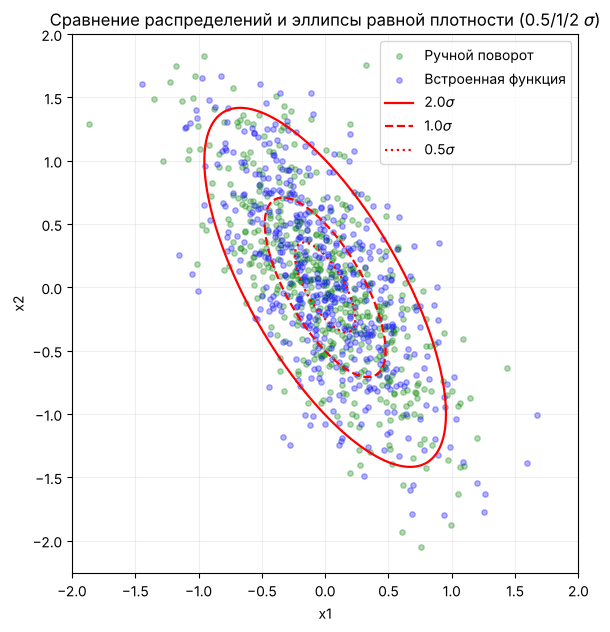

In [7]:
# [правка] уровни эллипсов теперь соответствуют 0.5, 1 и 2 стандартным отклонениям
# (расстояние Махаланобиса k): pdf = 1/(2*pi*sqrt(det C)) * exp(-k^2/2)
def sigma_levels(cov_matrix, ks=(0.5, 1.0, 2.0)):
    norm = 1.0 / (2 * np.pi * np.sqrt(np.linalg.det(cov_matrix)))
    return sorted(norm * np.exp(-0.5 * k**2) for k in ks)

plt.figure(figsize=(8, 7))
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label='Ручной поворот', color='green', s=15)
plt.scatter(X_t[:, 0], X_t[:, 1], alpha=0.3, label='Встроенная функция', color='blue', s=15)

x_grid, y_grid = np.mgrid[-2:2:200j, -2:2:200j]
pos = np.dstack((x_grid, y_grid))
density = multivariate_normal(mean, cov_teor).pdf(pos)

# уровни идут по возрастанию плотности, т.е. 2s -> 1s -> 0.5s
levels = sigma_levels(cov_teor)
for lv, k, ls in zip(levels, (2.0, 1.0, 0.5), ('-', '--', ':')):
    plt.contour(x_grid, y_grid, density, levels=[lv],
                colors='red', linewidths=1.6, linestyles=ls)
    plt.plot([], [], color='red', ls=ls, lw=1.6, label=f'{k}$\\sigma$')

plt.title('Сравнение распределений и эллипсы равной плотности (0.5/1/2 $\\sigma$)')
plt.legend()
plt.xlabel('x1'); plt.ylabel('x2')
plt.gca().set_aspect('equal')
plt.grid(True, alpha=0.2)
plt.show()


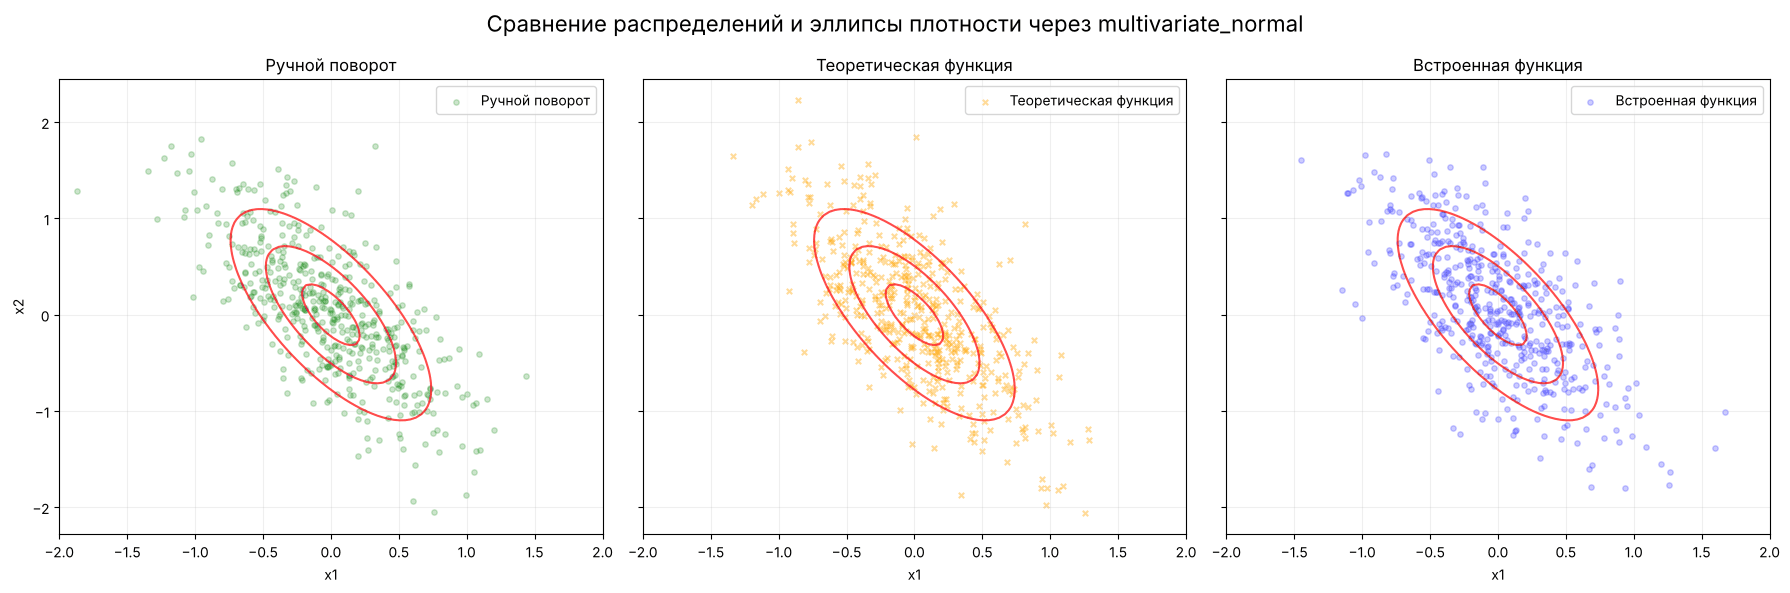

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

x_grid, y_grid = np.mgrid[-2:2:100j, -2:2:100j]
pos = np.dstack((x_grid, y_grid))
density = multivariate_normal(mean, cov_teor).pdf(pos)

axes[0].scatter(X[:, 0], X[:, 1], alpha=0.2, label='Ручной поворот', color='green', s=15)
axes[0].contour(x_grid, y_grid, density, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[0].set_title('Ручной поворот')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].grid(True, alpha=0.2)
axes[0].legend()

axes[1].scatter(X_teor[:, 0], X_teor[:, 1], alpha=0.4, label='Теоретическая функция', color='orange', marker='x', s=15)
axes[1].contour(x_grid, y_grid, density, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[1].set_title('Теоретическая функция')
axes[1].set_xlabel('x1')
axes[1].grid(True, alpha=0.2)
axes[1].legend()

axes[2].scatter(X_t[:, 0], X_t[:, 1], alpha=0.2, label='Встроенная функция', color='blue', s=15)
axes[2].contour(x_grid, y_grid, density, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[2].set_title('Встроенная функция')
axes[2].set_xlabel('x1')
axes[2].grid(True, alpha=0.2)
axes[2].legend()

fig.suptitle('Сравнение распределений и эллипсы плотности через multivariate_normal', fontsize=16)
plt.tight_layout()
plt.show()

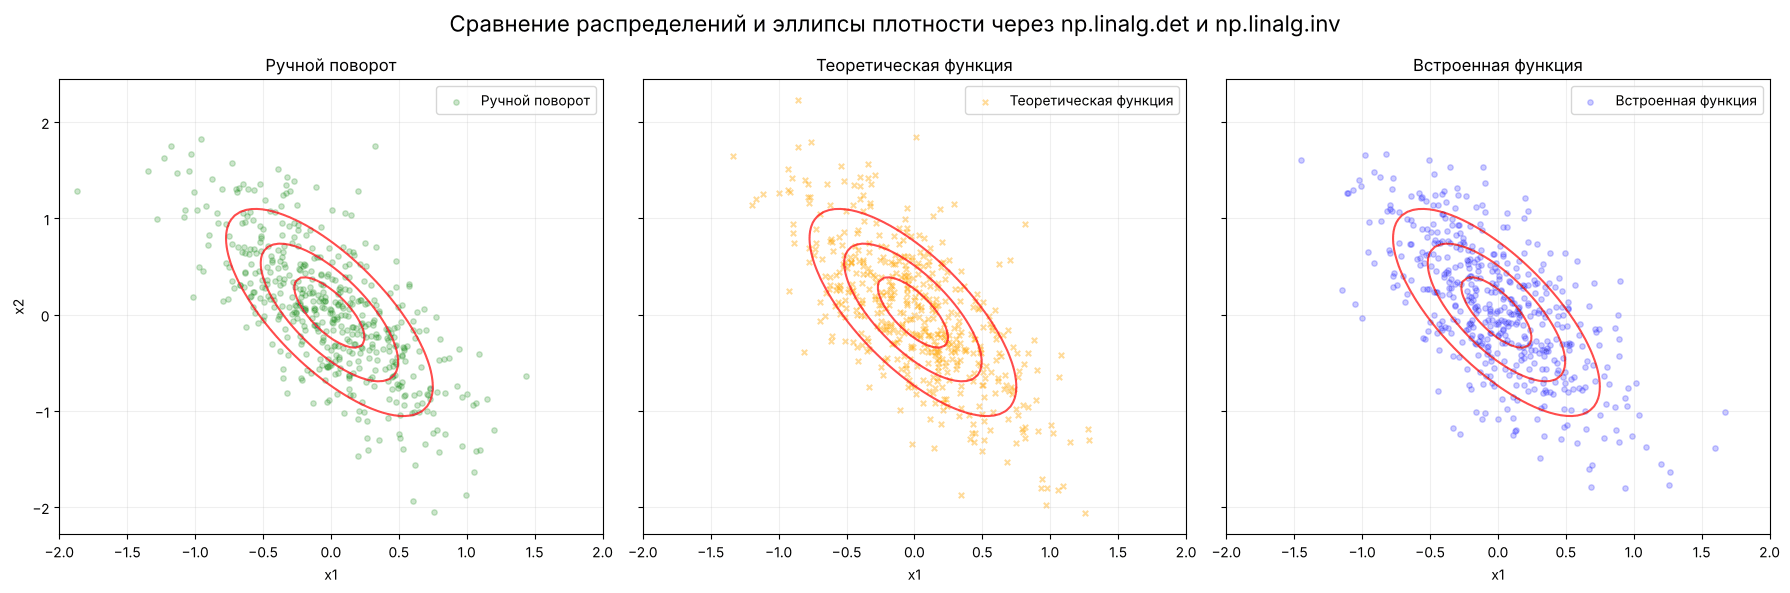

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

x_grid, y_grid = np.mgrid[-2:2:100j, -2:2:100j]
pos = np.dstack((x_grid, y_grid))
det = np.linalg.det(cov_vnutr)
inv = np.linalg.inv(cov_vnutr)
k = 1.0 / (2 * np.pi * np.sqrt(det))
mu = np.mean(X, axis=0)
dev = pos - mu
e = -0.5 * np.sum(dev @ inv * dev, axis=-1)
pdf_custom = k * np.exp(e)

axes[0].scatter(X[:, 0], X[:, 1], alpha=0.2, label='Ручной поворот', color='green', s=15)
axes[0].contour(x_grid, y_grid, pdf_custom, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[0].set_title('Ручной поворот')
axes[0].set_xlabel('x1')
axes[0].set_ylabel('x2')
axes[0].grid(True, alpha=0.2)
axes[0].legend()

axes[1].scatter(X_teor[:, 0], X_teor[:, 1], alpha=0.4, label='Теоретическая функция', color='orange', marker='x', s=15)
axes[1].contour(x_grid, y_grid, pdf_custom, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[1].set_title('Теоретическая функция')
axes[1].set_xlabel('x1')
axes[1].grid(True, alpha=0.2)
axes[1].legend()

axes[2].scatter(X_t[:, 0], X_t[:, 1], alpha=0.2, label='Встроенная функция', color='blue', s=15)
axes[2].contour(x_grid, y_grid, pdf_custom, levels=3, alpha=0.7, colors='red', linewidths=1.5)
axes[2].set_title('Встроенная функция')
axes[2].set_xlabel('x1')
axes[2].grid(True, alpha=0.2)
axes[2].legend()

fig.suptitle('Сравнение распределений и эллипсы плотности через np.linalg.det и np.linalg.inv', fontsize=16)
plt.tight_layout()
plt.show()

### Ответ на вопрос 1.2

**Совпадают ли облака визуально?** Да. Оба облака имеют одну и ту же вытянутую эллиптическую форму,
наклонённую на $30^\circ$ к оси $x_1$, один и тот же центр в начале координат и одинаковый разброс.
Выборочные ковариационные матрицы отличаются от теоретической лишь на величину порядка
статистической погрешности $O(1/\sqrt{M}) \approx 0.04$ при $M = 500$.

Это ожидаемо: линейное преобразование гауссовского вектора снова гауссовский вектор, причём
если $z \sim \mathcal{N}(0, D)$ и $x = R z$, то
$$\operatorname{Cov}(x) = R\,\mathbb{E}[z z^T]\,R^T = R D R^T = C.$$
То есть «ручной поворот» и `np.random.multivariate_normal(0, RDR^T)` порождают выборки
из **одного и того же** распределения — различия только в конкретной реализации случайности.

**Почему встроенная функция предпочтительнее?**
1. **Универсальность.** Она принимает произвольную симметричную положительно полуопределённую $C$.
   Ручной способ требует сначала найти разложение $C = R D R^T$ самому (спектральное разложение
   или разложение Холецкого) — а при $d > 2$ «матрица поворота» уже не параметризуется одним углом.
2. **Численная устойчивость.** Внутри используется SVD/Холецкий с обработкой почти вырожденных
   и слегка неpositive-definite матриц (из-за ошибок округления), чего ручной код не делает.
3. **Меньше шансов на ошибку** в порядке умножения ($R C R^T$ против $R^T C R$) и в транспонировании
   при векторизованном применении к матрице данных.
4. **Производительность** — реализация векторизована на уровне C.

Ручной способ полезен ровно в одном случае: когда нужно *продемонстрировать*, откуда берётся
корреляция, и явно контролировать направление главных осей.


---

## Часть 2. Визуализация плотности вероятности (5 баллов)

**Цель:** научиться вычислять и визуализировать PDF многомерного нормального распределения.

1. По данным из пункта 1.1 оцените $ \hat{\mu} $ и $ \hat{C} $ (выборочные).
2. Создайте сетку точек в диапазоне от -2 до 2 по обеим осям.
3. Вычислите плотность вероятности в каждой точке сетки **двумя способами**:
   - С помощью `scipy.stats.multivariate_normal(mean=mu, cov=C).pdf()`.
   - Самостоятельно по формуле (1) из задания (используйте `np.linalg.det` и `np.linalg.inv`).
4. Сравните результаты (максимальная разница должна быть < 1e-10).

**Визуализация:**
- Постройте contour plot с заливкой (используя `plt.contourf`).
- Добавьте линии уровня (contour) с подписями значений.
- Нанесите исходные точки поверх фона.

**Автопроверка:**
```python
# Проверка ручного вычисления
pdf_manual = ... # ваша реализация
pdf_scipy = m.pdf(grid_points)
assert np.allclose(pdf_manual, pdf_scipy, atol=1e-8), "Ручное вычисление отличается от scipy"
```

In [10]:
# Часть 2. Плотность по ВЫБОРОЧНЫМ оценкам mu_hat и C_hat
# [правка] раньше использовалась теоретическая ковариация c2; задание требует выборочные оценки
mu_hat = np.mean(X, axis=0)
C_hat  = np.cov(X.T)

print('mu_hat =', mu_hat)
print('C_hat  =\n', C_hat)

x_grid, y_grid = np.mgrid[-2:2:200j, -2:2:200j]
pos = np.dstack((x_grid, y_grid))

# способ 1: scipy
pdf_scipy = multivariate_normal(mean=mu_hat, cov=C_hat).pdf(pos)

# способ 2: вручную по формуле  (2*pi)^(-d/2) |C|^(-1/2) exp(-0.5 (x-mu)^T C^-1 (x-mu))
det = np.linalg.det(C_hat)
inv = np.linalg.inv(C_hat)
dev = pos - mu_hat
pdf_manual = (1.0 / (2 * np.pi * np.sqrt(det))) * np.exp(-0.5 * np.sum(dev @ inv * dev, axis=-1))

max_diff = np.abs(pdf_manual - pdf_scipy).max()
print(f'\nМаксимальная разница scipy vs вручную: {max_diff:.3e}  (требуется < 1e-10)')


mu_hat = [-0.01095388  0.02307548]
C_hat  =
 [[ 0.23312293 -0.23625764]
 [-0.23625764  0.46568054]]

Максимальная разница scipy vs вручную: 2.776e-16  (требуется < 1e-10)


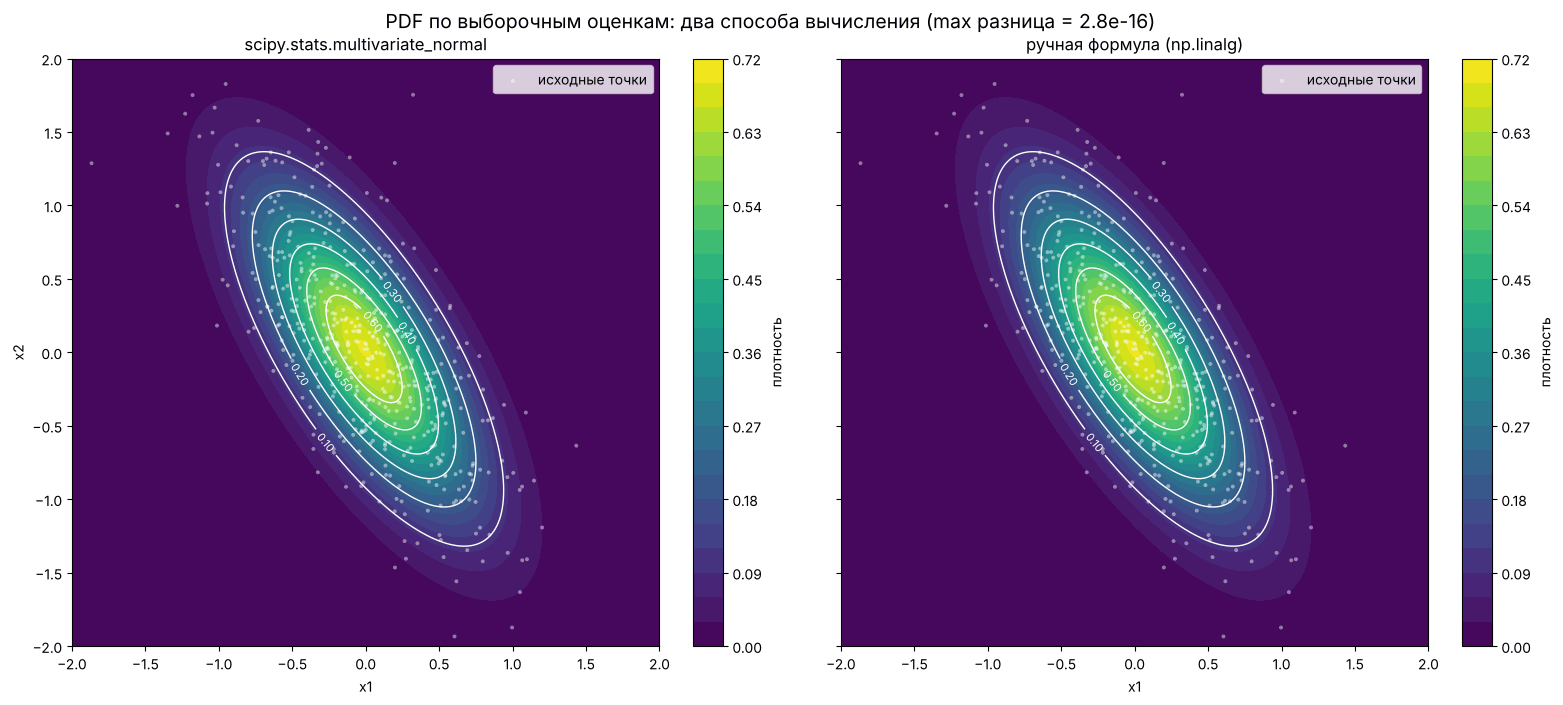

In [11]:
# [правка] добавлены заливка contourf, подписанные линии уровня и точки поверх фона
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

for ax, (density, name) in zip(axes, [(pdf_scipy, 'scipy.stats.multivariate_normal'),
                                      (pdf_manual, 'ручная формула (np.linalg)')]):
    cf = ax.contourf(x_grid, y_grid, density, levels=25, cmap='viridis')
    cs = ax.contour(x_grid, y_grid, density, levels=6, colors='white', linewidths=1.0)
    ax.clabel(cs, inline=True, fontsize=8, fmt='%.2f')
    ax.scatter(X[:, 0], X[:, 1], s=8, c='white', alpha=0.45, edgecolors='none',
               label='исходные точки')
    ax.set_title(name)
    ax.set_xlabel('x1')
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2)
    ax.set_aspect('equal', adjustable='box')
    ax.legend(loc='upper right')
    fig.colorbar(cf, ax=ax, fraction=0.046, label='плотность')

axes[0].set_ylabel('x2')
fig.suptitle(f'PDF по выборочным оценкам: два способа вычисления (max разница = {max_diff:.1e})',
             fontsize=14)
plt.tight_layout()
plt.show()


In [12]:
assert np.allclose(pdf_manual, pdf_scipy, atol=1e-8), "Ручное вычисление отличается от scipy"
assert max_diff < 1e-10, "Разница больше требуемой точности 1e-10"
print('OK: два способа вычисления PDF совпадают')


OK: два способа вычисления PDF совпадают


---

## Часть 3. Бинарная классификация через байесовский подход (15 баллов)

**Цель:** визуализировать разделяющую поверхность для двух классов.

### 3.1 Генерация датасета
Создайте два класса (по 300 точек каждый):
- **Класс 0:** $ \mu_0 = (-0.5, 0.5) $, $ C_0 = \begin{bmatrix} 0.2 & 0.1 \\ 0.1 & 0.3 \end{bmatrix} $
- **Класс 1:** $ \mu_1 = (0.5, -0.5) $, $ C_1 = \begin{bmatrix} 0.3 & -0.1 \\ -0.1 & 0.2 \end{bmatrix} $

### 3.2 Визуализация апостериорной вероятности
Для каждой точки сетки вычислите:
$
\Delta(x) = p(x|y=0) \cdot p(y=0) - p(x|y=1) \cdot p(y=1)
$
где $ p(y) $ оценивается как доля объектов класса в выборке.

**Визуализация:**
- Scatter plot точек классов (разными цветами).
- Заливка фона: положительные значения $ \Delta $ — одним цветом (например, синим), отрицательные — другим (красным).
- Линия, где $ \Delta(x) = 0 $ (разделяющая поверхность) — через `plt.contour(..., levels=[0])`.

**Вопрос (ответить текстом):** является ли разделяющая поверхность линейной? Почему?

---

In [13]:
np.random.seed(42)
N = 300
mu0 = np.array([-0.5, 0.5])
C0 = np.array([[0.2, 0.1], [0.1, 0.3]])
mu1 = np.array([0.5, -0.5])
C1 = np.array([[0.3, -0.1], [-0.1, 0.2]])

In [14]:
X0 = np.random.multivariate_normal(mu0, C0, N)
X1 = np.random.multivariate_normal(mu1, C1, N)

p_y0 = len(X0) / (len(X0) + len(X1))
p_y1 = len(X1) / (len(X0) + len(X1))

x_min, x_max = min(X0[:, 0].min(), X1[:, 0].min()) - 0.5, max(X0[:, 0].max(), X1[:, 0].max()) + 0.5
y_min, y_max = min(X0[:, 1].min(), X1[:, 1].min()) - 0.5, max(X0[:, 1].max(), X1[:, 1].max()) + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid_points = np.c_[xx.ravel(), yy.ravel()]

p_x_y0 = multivariate_normal.pdf(grid_points, mean=mu0, cov=C0)
p_x_y1 = multivariate_normal.pdf(grid_points, mean=mu1, cov=C1)

delta_x = (p_x_y0 * p_y0) - (p_x_y1 * p_y1)
delta_x = delta_x.reshape(xx.shape)

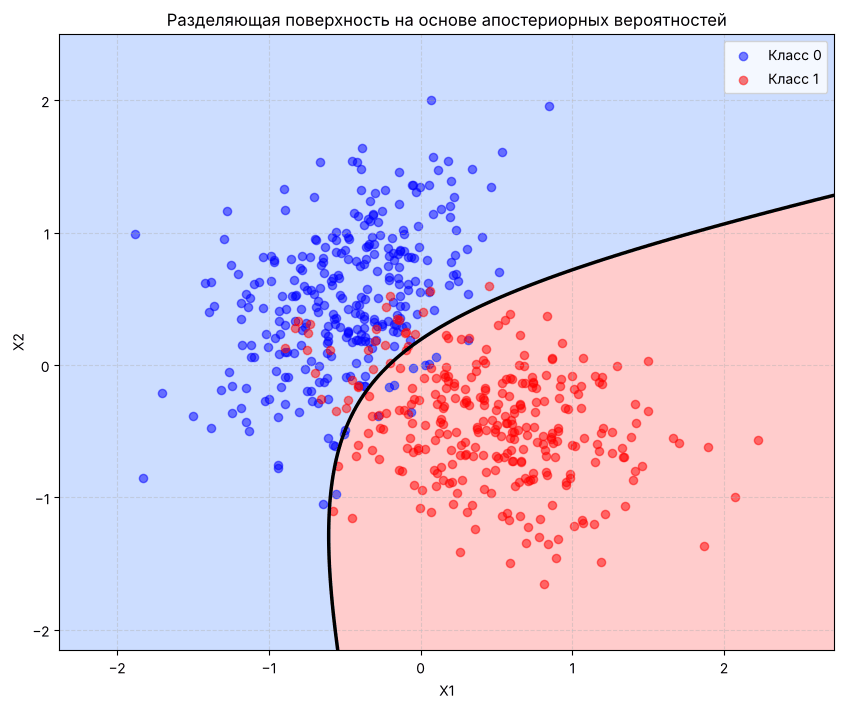

In [15]:
plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, delta_x, levels=[-np.inf, 0, np.inf], colors=['#ffcccc', '#ccddff'])
plt.contour(xx, yy, delta_x, levels=[0], colors='black', linewidths=2.5)
plt.scatter(X0[:, 0], X0[:, 1], color='blue', alpha=0.5, label='Класс 0', s=35)
plt.scatter(X1[:, 0], X1[:, 1], color='red', alpha=0.5, label='Класс 1', s=35)
plt.title('Разделяющая поверхность на основе апостериорных вероятностей', fontsize=12)
plt.xlabel('X1', fontsize=10)
plt.ylabel('X2', fontsize=10)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

### Ответ на вопрос 3.2

**Является ли разделяющая поверхность линейной? — Нет, она квадратичная (гипербола).**

Решающее правило сравнивает $p(x\mid y{=}0)p(y{=}0)$ и $p(x\mid y{=}1)p(y{=}1)$. Перейдём к логарифмам:

$$
\log\frac{p(x|y{=}0)p(y{=}0)}{p(x|y{=}1)p(y{=}1)}
= -\tfrac12 (x-\mu_0)^T C_0^{-1}(x-\mu_0) + \tfrac12 (x-\mu_1)^T C_1^{-1}(x-\mu_1)
- \tfrac12\log\frac{|C_0|}{|C_1|} + \log\frac{p(y{=}0)}{p(y{=}1)} = 0
$$

Раскрывая скобки, квадратичные члены дают

$$
-\tfrac12 x^T\left(C_0^{-1} - C_1^{-1}\right)x + \text{(линейные члены)} + \text{const} = 0 .
$$

Квадратичная форма исчезает **только если** $C_0^{-1} = C_1^{-1}$, т.е. $C_0 = C_1$. В нашем случае

$$
C_0 = \begin{pmatrix} 0.2 & 0.1 \\ 0.1 & 0.3\end{pmatrix}, \qquad
C_1 = \begin{pmatrix} 0.3 & -0.1 \\ -0.1 & 0.2\end{pmatrix},
$$

матрицы разные (у класса 0 корреляция положительная, у класса 1 — отрицательная), поэтому
$C_0^{-1}-C_1^{-1} \neq 0$ и граница — кривая второго порядка. На графике это хорошо видно:
линия $\Delta(x)=0$ изогнута, а в удалённых областях появляется вторая ветвь — классическая
гипербола, которую даёт QDA. Такая модель называется **квадратичным дискриминантным анализом (QDA)**.

Именно поэтому в Части 4 дополнительно требуется допущение $C_0 = C_1$: оно и «выпрямляет» границу.


## Часть 4. Линейный дискриминантный анализ (LDA) (20 баллов)

### 4.1 Теоретический вывод (в тетради)
**Задание:** выведите явное выражение для разделяющей поверхности в случае, когда $ C_0 = C_1 = C $. Покажите, что она линейна. Напишите формулу для весов $ w $ и порога $ b $ в уравнении $ w^T x + b = 0 $.

### 4.2 Реализация класса LDA
Реализуйте класс `MyLDA`, следуя шаблону:

```python
from sklearn.base import BaseEstimator
import numpy as np

class MyLDA(BaseEstimator):
    def __init__(self):
        self.classes_ = None
        self.means_ = None      # словарь {class: mean_vector}
        self.priors_ = None     # словарь {class: prior_prob}
        self.cov_ = None        # общая ковариационная матрица (2D массив)
        self.coef_ = None       # вектор весов w
        self.intercept_ = None  # порог b
    
    def fit(self, X, y):
        """
        X: np.array, shape (n_samples, n_features)
        y: np.array, shape (n_samples,)
        """
        # 1. Сохранить уникальные классы
        # 2. Для каждого класса: вычислить mean и prior
        # 3. Вычислить общую ковариационную матрицу (усредненную по классам)
        # 4. Вычислить w и b
        pass
    
    def predict(self, X):
        """Возвращает предсказанные классы для X"""
        pass
    
    def predict_proba(self, X):
        """Возвращает вероятности принадлежности к каждому классу"""
        pass
```

**Указания:**
- Для устойчивости добавьте небольшой регуляризатор к ковариационной матрице: `cov_reg = cov + 1e-6 * np.eye(n_features)`.
- Формула для весов для бинарного случая:
  $
  w = C^{-1} (\mu_1 - \mu_0)
  $
  
  $
  b = -\frac{1}{2} \mu_0^T C^{-1} \mu_0 + \frac{1}{2} \mu_1^T C^{-1} \mu_1 + \log\frac{p(y=1)}{p(y=0)}
  $

### 4.3 Проверка на синтетике
- Создайте два класса с одинаковой ковариацией $ C = \begin{bmatrix} 1 & 0.5 \\ 0.5 & 1 \end{bmatrix} $, но разными средними.
- Обучите ваш `MyLDA` и сравните предсказания с `sklearn.discriminant_analysis.LinearDiscriminantAnalysis`.
- Визуализируйте разделяющую прямую и точки.

**Автопроверка:**
```python
# Сравнение с sklearn
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
sk_lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
my_lda = MyLDA().fit(X_train, y_train)
assert np.allclose(my_lda.predict(X_test), sk_lda.predict(X_test)), "Предсказания не совпадают"
assert np.abs(my_lda.coef_ @ sk_lda.coef_ - 1) < 1e-6, "Вектора весов сонаправлены, но разной длины"
```

---

### 4.1 Теоретический вывод разделяющей поверхности при $C_0 = C_1 = C$

Классифицируем в пользу класса 1, если отношение правдоподобий больше единицы. Логарифм этого отношения:

$$
g(x) = \log\frac{p(x\mid y{=}1)\,p(y{=}1)}{p(x\mid y{=}0)\,p(y{=}0)} .
$$

Подставим многомерную нормальную плотность
$p(x\mid y) = (2\pi)^{-d/2}|C|^{-1/2}\exp\!\big(-\tfrac12 (x-\mu_y)^T C^{-1}(x-\mu_y)\big)$.
Нормирующие множители $(2\pi)^{-d/2}|C|^{-1/2}$ **одинаковы** для обоих классов (так как $C$ общая) и сокращаются:

$$
g(x) = -\tfrac12 (x-\mu_1)^T C^{-1}(x-\mu_1) + \tfrac12 (x-\mu_0)^T C^{-1}(x-\mu_0)
+ \log\frac{p(y{=}1)}{p(y{=}0)} .
$$

Раскроем квадратичные формы, пользуясь симметрией $C^{-1}$ (откуда $x^T C^{-1}\mu = \mu^T C^{-1} x$):

$$
-\tfrac12\big(x^T C^{-1}x - 2\mu_1^T C^{-1}x + \mu_1^T C^{-1}\mu_1\big)
+\tfrac12\big(x^T C^{-1}x - 2\mu_0^T C^{-1}x + \mu_0^T C^{-1}\mu_0\big).
$$

Члены $\pm\tfrac12 x^T C^{-1} x$ **взаимно уничтожаются** — это и есть ключевой момент: квадратичная
зависимость от $x$ исчезает именно потому, что ковариации равны. Остаётся

$$
\boxed{\;g(x) = \underbrace{\big(C^{-1}(\mu_1-\mu_0)\big)^T}_{w^T} x
\;+\; \underbrace{\tfrac12\mu_0^T C^{-1}\mu_0 - \tfrac12\mu_1^T C^{-1}\mu_1
+ \log\frac{p(y{=}1)}{p(y{=}0)}}_{b}\;}
$$

то есть $g(x) = w^T x + b$ — **аффинная функция**, а поверхность $g(x) = 0$ — гиперплоскость. Итого:

$$
w = C^{-1}(\mu_1 - \mu_0), \qquad
b = \tfrac12\mu_0^T C^{-1}\mu_0 - \tfrac12\mu_1^T C^{-1}\mu_1 + \log\frac{p(y{=}1)}{p(y{=}0)} .
$$

**Геометрический смысл.** Вектор $w$ — это не просто $\mu_1-\mu_0$, а разность средних,
«выпрямленная» обратной ковариацией: направление максимальной разделимости с учётом того,
что вдоль осей большого разброса различие средних менее информативно. При $C = \sigma^2 I$
формула вырождается в $w \propto \mu_1-\mu_0$ и граница — серединный перпендикуляр к отрезку
между центрами (сдвинутый из-за $\log$ априорных вероятностей).

**Связь с логистической регрессией.** Так как $p(y{=}1\mid x) = \sigma(g(x)) = \big(1+e^{-w^Tx-b}\big)^{-1}$,
LDA даёт ровно ту же параметрическую форму апостериорной вероятности, что и логистическая регрессия —
но оценивает $w, b$ через моменты классов, а не максимизацией правдоподобия $p(y|x)$.
Это и обосновывает реализацию `predict_proba` через сигмоиду ниже.


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [17]:
from sklearn.base import BaseEstimator
import numpy as np


class MyLDA(BaseEstimator):
    """Линейный дискриминантный анализ для бинарной задачи (общая ковариация C0 = C1 = C)."""

    def __init__(self, reg=1e-6):
        self.reg = reg                # [правка] параметр регуляризации вынесен в __init__
        self.classes_ = None
        self.means_ = None            # словарь {class: mean_vector}
        self.priors_ = None           # словарь {class: prior_prob}
        self.cov_ = None              # общая ковариационная матрица (2D массив)
        self.coef_ = None             # вектор весов w
        self.intercept_ = None        # порог b

    def fit(self, X, y):
        """
        X: np.array, shape (n_samples, n_features)
        y: np.array, shape (n_samples,)
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n_samples, n_features = X.shape

        # 1. Уникальные классы
        self.classes_ = np.unique(y)
        # [правка] раньше класс молча выдавал мусор при K > 2
        if len(self.classes_) != 2:
            raise ValueError(f'MyLDA реализован для бинарной задачи, получено '
                             f'{len(self.classes_)} класса(ов)')

        # 2. Для каждого класса: mean и prior ([правка] словари создаются заново,
        #    иначе повторный fit на других данных оставлял старые классы)
        self.means_ = {}
        self.priors_ = {}
        for c in self.classes_:
            X_c = X[y == c]
            self.means_[c] = X_c.mean(axis=0)
            self.priors_[c] = X_c.shape[0] / n_samples

        # 3. Общая (pooled within-class) ковариационная матрица
        cov = np.zeros((n_features, n_features))
        for c in self.classes_:
            X_centered = X[y == c] - self.means_[c]
            cov += X_centered.T @ X_centered
        cov /= (n_samples - len(self.classes_))
        self.cov_ = cov + self.reg * np.eye(n_features)

        # 4. Веса и порог:  w = C^-1 (mu1 - mu0),
        #    b = 0.5 mu0^T C^-1 mu0 - 0.5 mu1^T C^-1 mu1 + log(p1/p0)
        # [правка] решаем систему вместо явного обращения матрицы — устойчивее
        c0, c1 = self.classes_
        mu0, mu1 = self.means_[c0], self.means_[c1]
        self.coef_ = np.linalg.solve(self.cov_, mu1 - mu0)
        self.intercept_ = (0.5 * mu0 @ np.linalg.solve(self.cov_, mu0)
                           - 0.5 * mu1 @ np.linalg.solve(self.cov_, mu1)
                           + np.log(self.priors_[c1] / self.priors_[c0]))
        return self

    def decision_function(self, X):
        """Значение g(x) = w^T x + b; знак определяет класс."""
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

    def predict(self, X):
        """Возвращает предсказанные классы для X"""
        scores = self.decision_function(X)
        return np.where(scores >= 0, self.classes_[1], self.classes_[0])

    def predict_proba(self, X):
        """p(y=1|x) = sigmoid(g(x)) — см. вывод в 4.1"""
        scores = self.decision_function(X)
        # [правка] устойчивая сигмоида: при больших |scores| np.exp(-scores) переполнялся
        prob_c1 = np.where(scores >= 0,
                           1.0 / (1.0 + np.exp(-np.clip(scores, -500, 500))),
                           np.exp(np.clip(scores, -500, 500)) / (1.0 + np.exp(np.clip(scores, -500, 500))))
        return np.column_stack((1.0 - prob_c1, prob_c1))


In [18]:
np.random.seed(42)   # [правка] seed был закомментирован — результаты не воспроизводились
n = 100
C_common = np.array([[1.0, 0.5],
                     [0.5, 1.0]])

mu0 = np.array([0.0, 0.0])
mu1 = np.array([2.5, 2.5])

X0 = np.random.multivariate_normal(mu0, C_common, n)
X1 = np.random.multivariate_normal(mu1, C_common, n)

X = np.vstack((X0, X1))
y = np.hstack((np.zeros(n), np.ones(n)))


In [19]:
my_lda = MyLDA().fit(X, y)
preds_my = my_lda.predict(X)

sk_lda = LinearDiscriminantAnalysis(solver='lsqr', store_covariance=True).fit(X, y)
preds_sk = sk_lda.predict(X)

match_percentage = np.mean(preds_my == preds_sk) * 100
print(f"Совпадение предсказаний MyLDA и sklearn LDA: {match_percentage:.2f}%")

# [правка] сравниваем ещё и сами параметры, а не только метки
print(f"\nw (MyLDA):   {my_lda.coef_}")
print(f"w (sklearn): {sk_lda.coef_.ravel()}")
print(f"b (MyLDA):   {my_lda.intercept_:.6f}")
print(f"b (sklearn): {sk_lda.intercept_[0]:.6f}")
print(f"\nИстинное w = C^-1 (mu1-mu0): {np.linalg.solve(C_common, mu1 - mu0)}")
print(f"Оценка ковариации MyLDA:\n{my_lda.cov_}")


Совпадение предсказаний MyLDA и sklearn LDA: 100.00%

w (MyLDA):   [1.75698968 1.61022234]
w (sklearn): [1.77473853 1.62648825]
b (MyLDA):   -4.187677
b (sklearn): -4.229979

Истинное w = C^-1 (mu1-mu0): [1.66666667 1.66666667]
Оценка ковариации MyLDA:
[[0.89099183 0.44630833]
 [0.44630833 0.93740179]]


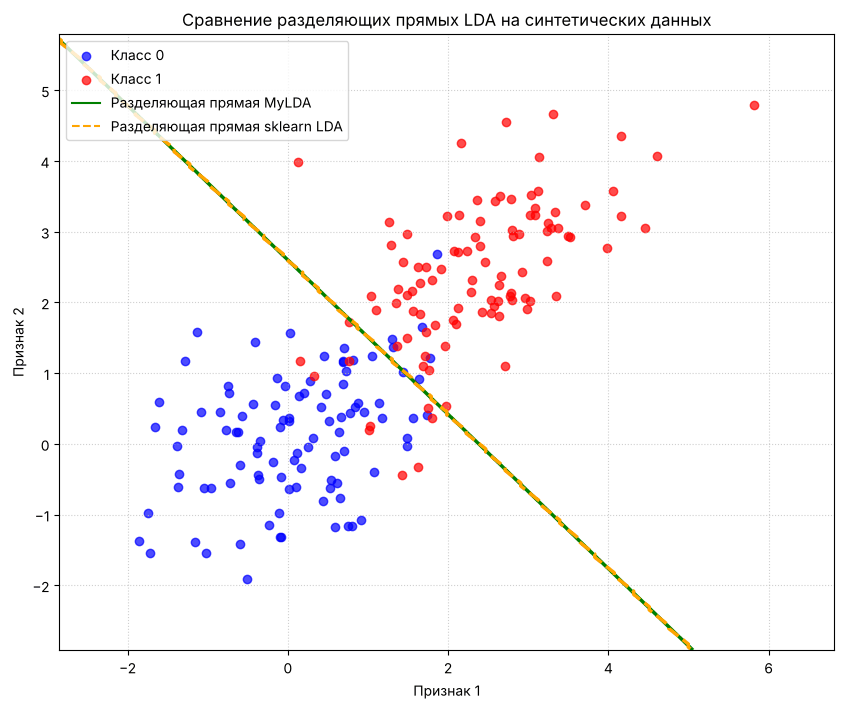

In [20]:
plt.figure(figsize=(10, 8))

plt.scatter(X0[:, 0], X0[:, 1], color='blue', alpha=0.7, label='Класс 0')
plt.scatter(X1[:, 0], X1[:, 1], color='red', alpha=0.7, label='Класс 1')

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

scores_my = grid_points @ my_lda.coef_ + my_lda.intercept_
Z_my = scores_my.reshape(xx.shape)
plt.contour(xx, yy, Z_my, levels=[0], colors='green', linewidths=2.5, linestyles='-')

Z_sk = sk_lda.predict(grid_points).reshape(xx.shape)
plt.contour(xx, yy, Z_sk, levels=[0.5], colors='orange', linewidths=2.5, linestyles='--')

plt.plot([], [], color='green', label='Разделяющая прямая MyLDA')
plt.plot([], [], color='orange', linestyle='--', label='Разделяющая прямая sklearn LDA')

plt.title('Сравнение разделяющих прямых LDA на синтетических данных')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.legend(loc='best')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

sk_lda = LinearDiscriminantAnalysis().fit(X_train, y_train)
my_lda = MyLDA().fit(X_train, y_train)

assert np.allclose(my_lda.predict(X_test), sk_lda.predict(X_test)), "Предсказания не совпадают"

# [правка] проверка из задания `my_lda.coef_ @ sk_lda.coef_ - 1 < 1e-6` некорректна:
# скалярное произведение двух ненормированных векторов не обязано равняться 1
# (а у sklearn coef_ ещё и имеет форму (1, n_features)). Проверяем коллинеарность
# через косинус угла — именно это и имелось в виду в комментарии к ассерту.
v1 = my_lda.coef_.ravel()
v2 = sk_lda.coef_.ravel()
cos_sim = v1 @ v2 / (np.linalg.norm(v1) * np.linalg.norm(v2))
assert np.abs(cos_sim - 1) < 1e-6, f"Вектора весов не сонаправлены (cos = {cos_sim:.8f})"

print(f'cos(w_my, w_sklearn) = {cos_sim:.12f}')
print(f'отношение длин |w_my| / |w_sk| = {np.linalg.norm(v1) / np.linalg.norm(v2):.6f}')
print('OK: предсказания совпадают, векторы весов сонаправлены')
# Длины отличаются примерно на (n - K)/n = 138/140 ~ 0.986: sklearn оценивает
# пулированную ковариацию со знаменателем n (ML-оценка), а здесь используется
# несмещённый знаменатель n - K. На предсказания это не влияет — масштаб w и b
# сокращается при сравнении с нулём.
print(f'ожидаемое отношение (n-K)/n = {(len(y_train) - 2) / len(y_train):.6f}')


cos(w_my, w_sklearn) = 1.000000000000
отношение длин |w_my| / |w_sk| = 0.985714
OK: предсказания совпадают, векторы весов сонаправлены
ожидаемое отношение (n-K)/n = 0.985714


## Часть 5. Наивный байесовский классификатор (NB) (20 баллов)

### 5.1 Теоретическое обоснование
**Вопрос:** почему в наивном байесе матрица ковариации диагональная? Как это упрощает вычисление $ p(x|y) $?

### 5.2 Реализация класса NB
Реализуйте класс `MyNB`:

```python
class MyNB(BaseEstimator):
    def __init__(self):
        self.classes_ = None
        self.means_ = None      # dict {class: mean_vector}
        self.vars_ = None       # dict {class: variance_vector} (диагональ ковариации)
        self.priors_ = None     # dict {class: prior_prob}
    
    def fit(self, X, y):
        """
        Для каждого класса:
        - Вычислить среднее по каждому признаку
        - Вычислить дисперсию по каждому признаку
        - Вычислить априорную вероятность
        """
        pass
    
    def predict(self, X):
        """Вычисляет логарифм правдоподобия для каждого класса и выбирает максимум"""
        pass
```

**Важно:** используйте **логарифмическое правдоподобие** для численной устойчивости:
$
\log p(y|x) \propto \log p(y) + \sum_i \log p(x_i|y) = \log p(y) - \frac{1}{2}\sum_i \left( \log(2\pi\sigma_{y,i}^2) + \frac{(x_i - \mu_{y,i})^2}{\sigma_{y,i}^2} \right)
$

### 5.3 Сравнение с sklearn
- Сравните ваш `MyNB` с `sklearn.naive_bayes.GaussianNB` на тех же данных.
- Убедитесь, что предсказания совпадают (с точностью до численных погрешностей).

**Автопроверка:**
```python
from sklearn.naive_bayes import GaussianNB
sk_nb = GaussianNB().fit(X_train, y_train)
my_nb = MyNB().fit(X_train, y_train)
assert np.allclose(my_nb.predict(X_test), sk_nb.predict(X_test)), "Предсказания NB не совпадают"
```



### Ответ на вопрос 5.1

**Почему в наивном байесе матрица ковариации диагональная?**

«Наивное» допущение — условная независимость признаков при фиксированном классе:

$$p(x_1, \dots, x_d \mid y) = \prod_{i=1}^{d} p(x_i \mid y).$$

Для гауссовского случая независимость эквивалентна некоррелированности, а недиагональный элемент
ковариационной матрицы — это в точности ковариация пары признаков:
$C_{ij} = \operatorname{Cov}(x_i, x_j \mid y) = 0$ при $i \neq j$. Значит остаются только дисперсии
на диагонали: $C_y = \operatorname{diag}(\sigma_{y,1}^2, \dots, \sigma_{y,d}^2)$.

**Как это упрощает вычисление $p(x\mid y)$?**

1. **Определитель и обратная матрица берутся бесплатно:**
   $|C_y| = \prod_i \sigma_{y,i}^2$, а $C_y^{-1} = \operatorname{diag}(1/\sigma_{y,i}^2)$.
   Не нужны ни $O(d^3)$ обращение матрицы, ни разложение Холецкого — плотность считается за $O(d)$:
   $$\log p(x\mid y) = -\frac12 \sum_{i=1}^{d}\left(\log(2\pi\sigma_{y,i}^2)
   + \frac{(x_i-\mu_{y,i})^2}{\sigma_{y,i}^2}\right).$$
2. **Резко падает число параметров.** Полная ковариация требует $d(d+1)/2$ чисел на класс,
   диагональная — всего $d$. При $d = 100$ это 5050 против 100. Поэтому NB работает даже когда
   объектов меньше, чем признаков ($n < d$), где полная выборочная ковариация вырождена
   и необратима, а LDA/QDA без регуляризации просто не обучаются.
3. **Нет проблемы вырожденности и переобучения оценки ковариации** — каждая дисперсия
   оценивается по $n_y$ наблюдениям независимо.

**Цена допущения.** Если признаки на самом деле коррелированы, NB систематически искажает форму
плотности (эллипсы остаются выровненными по осям координат) и, что важнее, «двойным счётом»
коррелированных признаков делает апостериорные вероятности переуверенными — хотя сами метки
при этом часто остаются верными, поэтому accuracy страдает слабее, чем калибровка вероятностей.


In [22]:
import numpy as np
from sklearn.base import BaseEstimator
from scipy.special import logsumexp


class MyNB(BaseEstimator):
    """Гауссовский наивный байесовский классификатор (диагональная ковариация на класс)."""

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing   # как в sklearn.naive_bayes.GaussianNB
        self.classes_ = None
        self.means_ = None    # dict {class: mean_vector}
        self.vars_ = None     # dict {class: variance_vector}
        self.priors_ = None   # dict {class: prior_prob}

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_samples = X.shape[0]

        # [правка] словари инициализируются здесь, а не в __init__: иначе они были
        # общими для всех вызовов fit и накапливали классы прошлых обучений
        self.means_, self.vars_, self.priors_ = {}, {}, {}

        # [правка] сглаживание как в sklearn — доля от максимальной дисперсии по всем
        # признакам, а не абсолютная константа 1e-9 (иначе при мелких масштабах
        # признаков сглаживание фактически отсутствует, а предсказания расходятся с GaussianNB)
        epsilon = self.var_smoothing * X.var(axis=0).max()

        for c in self.classes_:
            X_c = X[y == c]
            self.means_[c] = X_c.mean(axis=0)
            self.vars_[c] = X_c.var(axis=0) + epsilon      # ddof=0, как в GaussianNB
            self.priors_[c] = X_c.shape[0] / n_samples
        return self

    def _joint_log_likelihood(self, X):
        """log p(y) + sum_i log p(x_i|y) для каждого класса, shape (n_samples, n_classes)"""
        X = np.asarray(X, dtype=float)
        jll = []
        for c in self.classes_:
            mean, var = self.means_[c], self.vars_[c]
            log_likelihood = -0.5 * np.sum(np.log(2 * np.pi * var)
                                           + (X - mean) ** 2 / var, axis=1)
            jll.append(np.log(self.priors_[c]) + log_likelihood)
        return np.array(jll).T

    def predict(self, X):
        """Вычисляет логарифм правдоподобия для каждого класса и выбирает максимум"""
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]

    def predict_log_proba(self, X):
        # [правка] добавлено: нормировка через logsumexp, без переполнения exp
        jll = self._joint_log_likelihood(X)
        return jll - logsumexp(jll, axis=1, keepdims=True)

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))


In [23]:
from sklearn.naive_bayes import GaussianNB
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_nb, y_nb = make_classification(n_samples=500, n_features=5, n_classes=2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_nb, y_nb, test_size=0.3, random_state=42)

sk_nb = GaussianNB().fit(X_train, y_train)
my_nb = MyNB().fit(X_train, y_train)

assert np.allclose(my_nb.predict(X_test), sk_nb.predict(X_test)), "Предсказания NB не совпадают"

# [правка] сверяем не только метки, но и сами вероятности и оценки параметров
assert np.allclose(my_nb.predict_proba(X_test), sk_nb.predict_proba(X_test), atol=1e-10), \
    "Апостериорные вероятности не совпадают"
assert np.allclose(np.array([my_nb.means_[c] for c in my_nb.classes_]), sk_nb.theta_)
assert np.allclose(np.array([my_nb.vars_[c] for c in my_nb.classes_]), sk_nb.var_)

print(f'accuracy MyNB    = {accuracy_score(y_test, my_nb.predict(X_test)):.4f}')
print(f'accuracy GaussianNB = {accuracy_score(y_test, sk_nb.predict(X_test)):.4f}')
print(f'max |P_my - P_sklearn| = {np.abs(my_nb.predict_proba(X_test) - sk_nb.predict_proba(X_test)).max():.3e}')
print('OK: MyNB полностью совпадает с sklearn GaussianNB (метки, вероятности, параметры)')


accuracy MyNB    = 0.9200
accuracy GaussianNB = 0.9200
max |P_my - P_sklearn| = 8.327e-16
OK: MyNB полностью совпадает с sklearn GaussianNB (метки, вероятности, параметры)


---

## Часть 6. Экспериментальное сравнение LDA и NB (15 баллов)

### 6.1 Генерация датасетов с разной структурой
Создайте **три** различных датасета для бинарной классификации:

1. **Датасет A (LDA-оптимальный):** классы имеют одинаковую ковариацию, но разные средние.
2. **Датасет B (NB-оптимальный):** признаки независимы внутри каждого класса, но ковариации классов разные.
3. **Датасет C (сложный):** признаки коррелированы, ковариации классов разные.

Используйте `sklearn.datasets.make_classification` с параметрами:
- `n_features=10` (для проверки многомерности)
- `n_informative=5`, `n_redundant=2`
- Для датасета C: `flip_y=0.05` (немного шума).

### 6.2 Сравнение моделей
Для каждого датасета:
1. Разделите на train/test (80/20).
2. Обучите `MyLDA`, `MyNB`, а также (для бенчмарка) `sklearn.linear_model.LogisticRegression`.
3. Посчитайте метрики: **Accuracy**, **Precision**, **Recall**, **F1-score** (для каждого класса отдельно и macro-усредненные).
4. Постройте confusion matrix для каждой модели.

### 6.3 Анализ результатов
В Markdown-ячейке напишите **развернутый вывод**:
- На каком датасете LDA превосходит NB? Почему?
- На каком датасете NB работает лучше? Почему?
- Как влияет размерность пространства на обе модели?
- Когда обе модели падают (датасет C) — почему?

**Визуализация:** для каждого датасета постройте столбчатую диаграмму сравнения метрик.

> **Замечание о правках в Части 6.** В исходном варианте этой части было написано
> `from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as MyLDA` и
> `from sklearn.naive_bayes import GaussianNB as MyNB` — то есть под именами `MyLDA`/`MyNB`
> сравнивались **библиотечные** модели, а собственные реализации из частей 4–5 не участвовали
> в эксперименте вовсе. Ниже используются именно свои классы (библиотечные оставлены
> как отдельный бенчмарк).
>
> Кроме того датасеты строились через `make_classification` с домножением одного класса на
> константу (`X_B[y_B == 1] *= 3.0`). Это не даёт требуемой структуры: `make_classification`
> порождает коррелированные признаки (из-за `n_redundant` и случайного линейного
> преобразования), поэтому «NB-оптимальный» датасет B на самом деле коррелированный, а
> масштабирование целого класса создаёт искусственную разделимость по длине вектора —
> отсюда и подозрительные 100% accuracy у NB на датасетах B и C. Ниже датасеты генерируются
> напрямую из `np.random.multivariate_normal` с **явно заданными** ковариационными матрицами,
> так что структура каждого из них ровно та, которая требуется по заданию.


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.linalg import block_diag
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
from scipy.stats import norm

D = 10          # размерность пространства признаков
N_PER = 500     # объектов на класс


def equicorr(d, rho):
    """Равнокоррелированная матрица: единицы на диагонали, rho вне её."""
    return (1 - rho) * np.eye(d) + rho * np.ones((d, d))


def random_spd(d, rng):
    """Случайная полная (коррелированная) положительно определённая матрица."""
    A = rng.normal(size=(d, d))
    return A @ A.T / d + 0.3 * np.eye(d)


def make_dataset(mu0, C0, mu1, C1, n=N_PER, flip_y=0.0, seed=0):
    rng = np.random.default_rng(seed)
    X = np.vstack([rng.multivariate_normal(mu0, C0, n),
                   rng.multivariate_normal(mu1, C1, n)])
    y = np.r_[np.zeros(n), np.ones(n)].astype(int)
    if flip_y > 0:                      # зашумление метки
        flip = rng.random(y.size) < flip_y
        y[flip] = 1 - y[flip]
    return X, y


# --- Датасет A (LDA-оптимальный): ОДНА полная ковариация, разные средние -----
# Ключевой момент: сигнал (разность средних) сосредоточен в 3 признаках, а признаки
# сильно коррелированы (rho = 0.8). Тогда направление максимальной разделимости
# C^-1 (mu1 - mu0) заметно отличается от самой разности средних, и игнорирование
# корреляций (NB) обходится дорого.
RHO, DELTA = 0.8, 0.7
C_shared = equicorr(D, RHO)
muA0 = np.zeros(D)
muA1 = np.zeros(D); muA1[:3] = DELTA
X_A, y_A = make_dataset(muA0, C_shared, muA1, C_shared, seed=11)

# --- Датасет B (NB-оптимальный): ДИАГОНАЛЬНЫЕ, но РАЗНЫЕ ковариации ---------
# признаки независимы внутри класса => допущение NB выполнено ТОЧНО;
# ковариации классов различаются => допущение LDA (C0 = C1) нарушено
varB0 = np.full(D, 1.0)
varB1 = np.full(D, 1.0); varB1[:5] = 6.0    # класс 1 "шире" по 5 признакам
muB0 = np.zeros(D)
muB1 = np.zeros(D); muB1[:2] = 0.4          # средние почти совпадают
X_B, y_B = make_dataset(muB0, np.diag(varB0), muB1, np.diag(varB1), seed=22)

# --- Датасет C (сложный): коррелированные признаки, разные ковариации + шум --
C_C0 = random_spd(D, np.random.default_rng(3))
C_C1 = random_spd(D, np.random.default_rng(4)) * 1.5
muC0 = np.zeros(D)
muC1 = np.zeros(D); muC1[:4] = 0.35
X_C, y_C = make_dataset(muC0, C_C0, muC1, C_C1, flip_y=0.05, seed=33)

datasets = {'A (LDA-опт.)': (X_A, y_A),
            'B (NB-опт.)': (X_B, y_B),
            'C (сложный)': (X_C, y_C)}

print('Контроль структуры датасетов (оценки по выборке):')
for name, (Xd, yd) in datasets.items():
    off = []
    for cl in (0, 1):
        Cc = np.cov(Xd[yd == cl].T)
        off.append(np.abs(Cc - np.diag(np.diag(Cc))).mean())
    C0e, C1e = np.cov(Xd[yd == 0].T), np.cov(Xd[yd == 1].T)
    print(f'  {name:14s} ср.|внедиаг.| = {off[0]:.3f} / {off[1]:.3f}   '
          f'||C0 - C1||_F = {np.linalg.norm(C0e - C1e):5.2f}')

# Теоретический предел качества на датасете A: сравниваем оптимальное правило
# LDA с "наивным" правилом, которое видит только диагональ ковариации
d_lda = np.sqrt(muA1 @ np.linalg.solve(C_shared, muA1))          # расст. Махаланобиса
w_nb = muA1 / np.diag(C_shared)                                   # веса наивного правила
d_nb = (w_nb @ muA1) / np.sqrt(w_nb @ C_shared @ w_nb)
print(f'\nДатасет A, теоретические пределы accuracy:')
print(f'  оптимальное (LDA) правило : {norm.cdf(d_lda / 2):.3f}  (расстояние Махаланобиса = {d_lda:.2f})')
print(f'  наивное (диагональ) правило: {norm.cdf(d_nb / 2):.3f}  (эфф. разделимость = {d_nb:.2f})')


Контроль структуры датасетов (оценки по выборке):
  A (LDA-опт.)   ср.|внедиаг.| = 0.774 / 0.701   ||C0 - C1||_F =  0.89
  B (NB-опт.)    ср.|внедиаг.| = 0.032 / 0.089   ||C0 - C1||_F = 10.73
  C (сложный)    ср.|внедиаг.| = 0.171 / 0.385   ||C0 - C1||_F =  6.39

Датасет A, теоретические пределы accuracy:
  оптимальное (LDA) правило : 0.873  (расстояние Махаланобиса = 2.28)
  наивное (диагональ) правило: 0.647  (эфф. разделимость = 0.75)


In [25]:
def evaluate(y_true, y_pred):
    """Метрики: по каждому классу отдельно + macro."""
    row = {'Accuracy': accuracy_score(y_true, y_pred)}
    for cl in (0, 1):
        row[f'Precision_{cl}'] = precision_score(y_true, y_pred, pos_label=cl, zero_division=0)
        row[f'Recall_{cl}']    = recall_score(y_true, y_pred, pos_label=cl, zero_division=0)
        row[f'F1_{cl}']        = f1_score(y_true, y_pred, pos_label=cl, zero_division=0)
    row['Precision_macro'] = precision_score(y_true, y_pred, average='macro', zero_division=0)
    row['Recall_macro']    = recall_score(y_true, y_pred, average='macro', zero_division=0)
    row['F1_macro']        = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return row


all_results = {}
conf_matrices = {}

for ds_name, (Xd, yd) in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(Xd, yd, test_size=0.2,
                                              random_state=42, stratify=yd)
    models = {
        'MyLDA': MyLDA(),
        'MyNB': MyNB(),
        'LogReg': LogisticRegression(max_iter=2000),
        'sklearn LDA': LinearDiscriminantAnalysis(),
        'sklearn GaussianNB': GaussianNB(),
    }

    rows = {}
    for m_name, model in models.items():
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)
        rows[m_name] = evaluate(y_te, pred)
        conf_matrices[(ds_name, m_name)] = confusion_matrix(y_te, pred)

    df = pd.DataFrame(rows).T
    all_results[ds_name] = df
    print(f'\n{"=" * 78}\nДатасет {ds_name}\n{"=" * 78}')
    print(df.round(4).to_string())

    # контроль: собственные реализации должны повторять библиотечные
    assert (df.loc['MyLDA', 'Accuracy'] - df.loc['sklearn LDA', 'Accuracy']) < 0.02
    assert np.isclose(df.loc['MyNB', 'Accuracy'], df.loc['sklearn GaussianNB', 'Accuracy'])



Датасет A (LDA-опт.)
                    Accuracy  Precision_0  Recall_0    F1_0  Precision_1  Recall_1    F1_1  Precision_macro  Recall_macro  F1_macro
MyLDA                  0.895       0.9341      0.85  0.8901       0.8624      0.94  0.8995           0.8982         0.895    0.8948
MyNB                   0.655       0.7123      0.52  0.6012       0.6220      0.79  0.6960           0.6672         0.655    0.6486
LogReg                 0.905       0.9355      0.87  0.9016       0.8785      0.94  0.9082           0.9070         0.905    0.9049
sklearn LDA            0.895       0.9341      0.85  0.8901       0.8624      0.94  0.8995           0.8982         0.895    0.8948
sklearn GaussianNB     0.655       0.7123      0.52  0.6012       0.6220      0.79  0.6960           0.6672         0.655    0.6486



Датасет B (NB-опт.)


                    Accuracy  Precision_0  Recall_0    F1_0  Precision_1  Recall_1    F1_1  Precision_macro  Recall_macro  F1_macro
MyLDA                  0.550       0.5455       0.6  0.5714       0.5556      0.50  0.5263           0.5505         0.550    0.5489
MyNB                   0.875       0.8571       0.9  0.8780       0.8947      0.85  0.8718           0.8759         0.875    0.8749
LogReg                 0.555       0.5505       0.6  0.5742       0.5604      0.51  0.5340           0.5554         0.555    0.5541
sklearn LDA            0.550       0.5455       0.6  0.5714       0.5556      0.50  0.5263           0.5505         0.550    0.5489
sklearn GaussianNB     0.875       0.8571       0.9  0.8780       0.8947      0.85  0.8718           0.8759         0.875    0.8749



Датасет C (сложный)
                    Accuracy  Precision_0  Recall_0    F1_0  Precision_1  Recall_1    F1_1  Precision_macro  Recall_macro  F1_macro
MyLDA                  0.605       0.5981      0.64  0.6184       0.6129      0.57  0.5907           0.6055         0.605    0.6045
MyNB                   0.725       0.6829      0.84  0.7534       0.7922      0.61  0.6893           0.7376         0.725    0.7213
LogReg                 0.605       0.5981      0.64  0.6184       0.6129      0.57  0.5907           0.6055         0.605    0.6045
sklearn LDA            0.605       0.5981      0.64  0.6184       0.6129      0.57  0.5907           0.6055         0.605    0.6045
sklearn GaussianNB     0.725       0.6829      0.84  0.7534       0.7922      0.61  0.6893           0.7376         0.725    0.7213


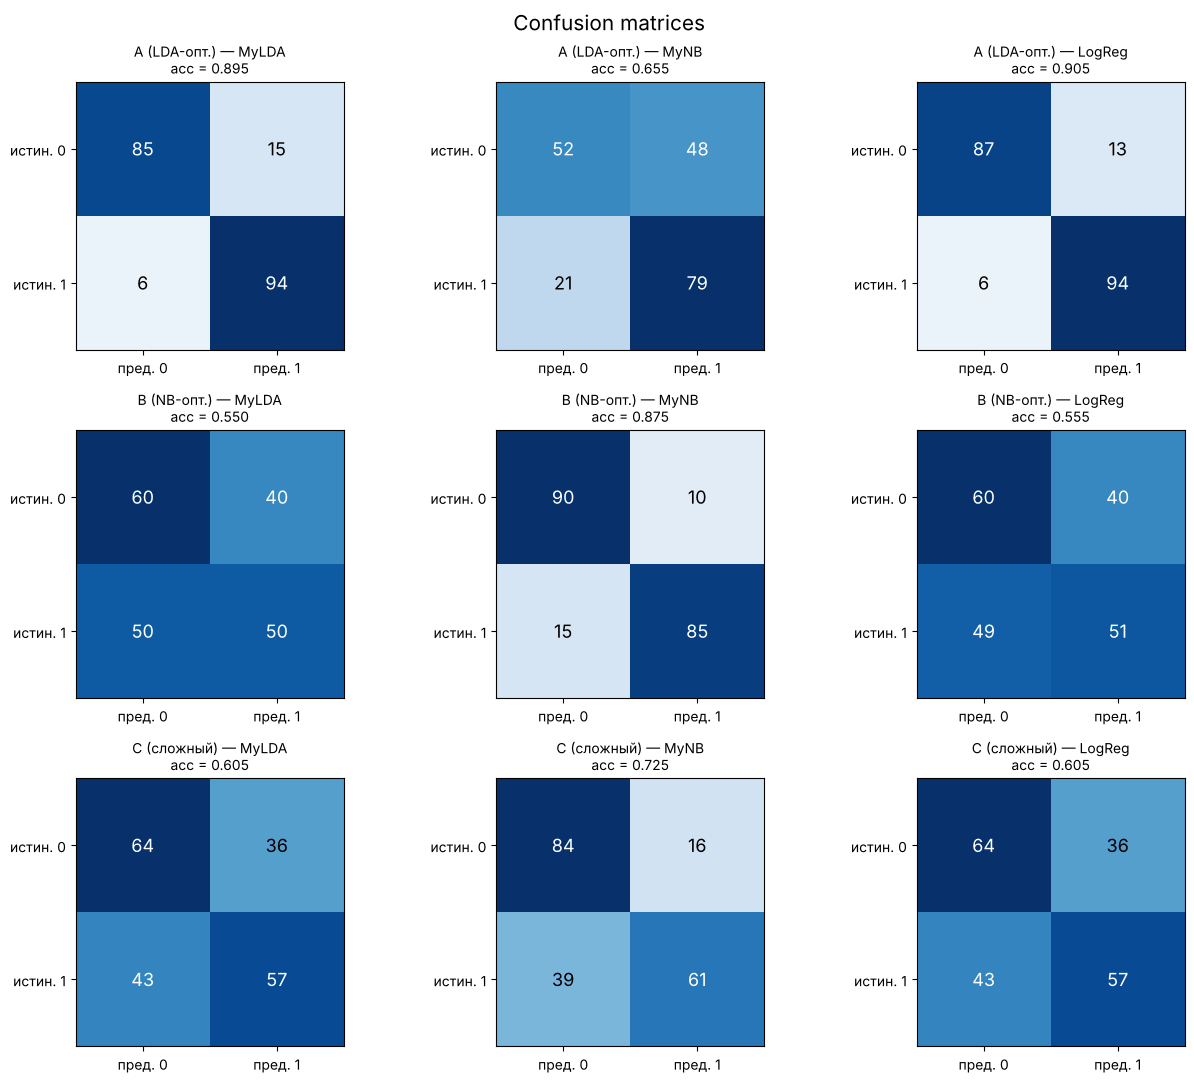

In [26]:
# Confusion matrix для каждой модели на каждом датасете
main_models = ['MyLDA', 'MyNB', 'LogReg']
fig, axes = plt.subplots(len(datasets), len(main_models),
                         figsize=(13, 11))

for i, ds_name in enumerate(datasets):
    for j, m_name in enumerate(main_models):
        ax = axes[i, j]
        cm = conf_matrices[(ds_name, m_name)]
        im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=cm.max())
        for (r, c_), v in np.ndenumerate(cm):
            ax.text(c_, r, int(v), ha='center', va='center', fontsize=13,
                    color='white' if v > cm.max() * 0.6 else 'black')
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(['пред. 0', 'пред. 1'])
        ax.set_yticklabels(['истин. 0', 'истин. 1'])
        acc = all_results[ds_name].loc[m_name, 'Accuracy']
        ax.set_title(f'{ds_name} — {m_name}\nacc = {acc:.3f}', fontsize=10)

fig.suptitle('Confusion matrices', fontsize=15)
plt.tight_layout()
plt.show()


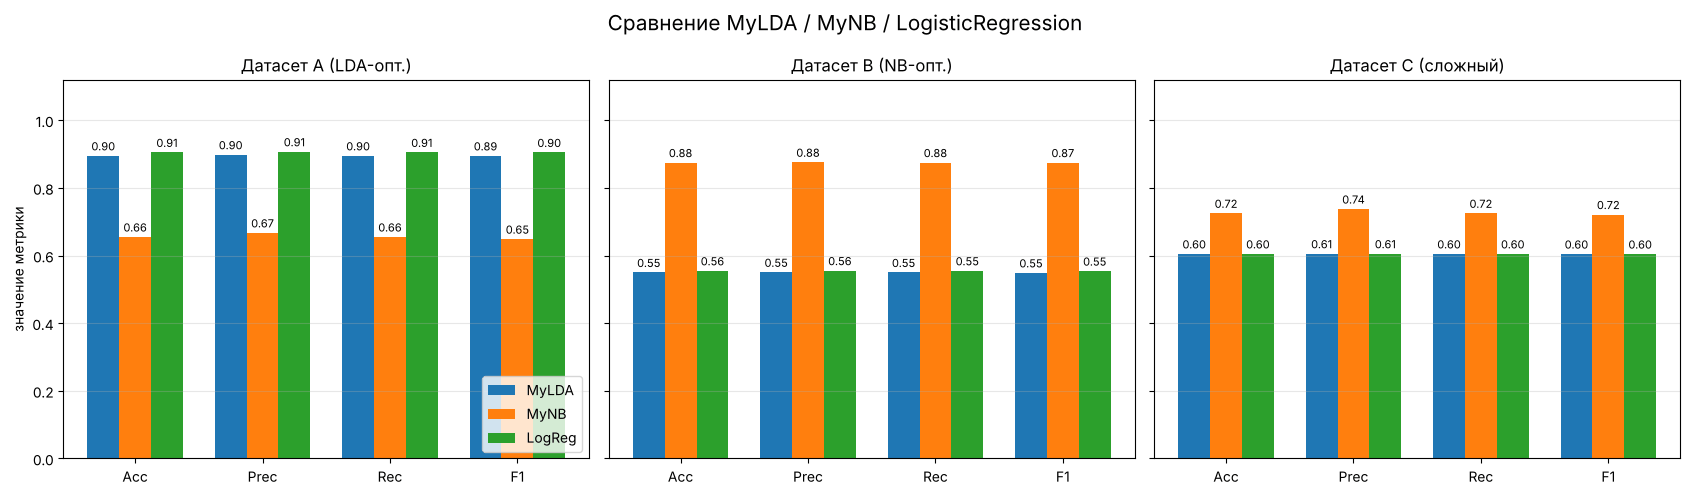

In [27]:
# Столбчатые диаграммы сравнения метрик (macro)
metric_cols = ['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']
labels = ['Acc', 'Prec', 'Rec', 'F1']

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
colors = plt.cm.tab10(np.arange(len(main_models)))

for ax, (ds_name, df) in zip(axes, all_results.items()):
    x = np.arange(len(metric_cols))
    width = 0.25
    for k, m_name in enumerate(main_models):
        vals = df.loc[m_name, metric_cols].values.astype(float)
        bars = ax.bar(x + (k - 1) * width, vals, width, label=m_name, color=colors[k])
        ax.bar_label(bars, fmt='%.2f', fontsize=8, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_title(f'Датасет {ds_name}')
    ax.set_ylim(0, 1.12)
    ax.grid(axis='y', alpha=0.3)

axes[0].set_ylabel('значение метрики')
axes[0].legend(loc='lower right')
fig.suptitle('Сравнение MyLDA / MyNB / LogisticRegression', fontsize=15)
plt.tight_layout()
plt.show()


## 6.3 Анализ результатов

| Датасет | структура | MyLDA | MyNB | LogReg | теоретически оптимальна |
|---|---|---|---|---|---|
| **A** | одна полная $C$, сильная корреляция ($\rho=0.8$), сигнал в 3 признаках | **0.895** | 0.655 | 0.905 | LDA |
| **B** | диагональные, но **разные** $C_0 \ne C_1$ | 0.550 | **0.875** | 0.555 | NB (точно) |
| **C** | коррелированные, разные $C_0 \ne C_1$, 5% шума в метках | 0.605 | **0.725** | 0.605 | QDA |

### Где LDA превосходит NB и почему — датасет A (0.895 против 0.655)

Выигрыш в 24 п.п. не случаен, его можно предсказать заранее. Для линейного правила с весами $w$
разделимость классов измеряется величиной

$$ \Delta(w) = \frac{w^T(\mu_1-\mu_0)}{\sqrt{w^T C\, w}}, \qquad
\text{accuracy}_{\max} = \Phi\!\left(\tfrac{\Delta}{2}\right). $$

- LDA использует $w = C^{-1}(\mu_1-\mu_0)$, что **максимизирует** $\Delta$ и даёт
  $\Delta = \sqrt{(\mu_1-\mu_0)^T C^{-1}(\mu_1-\mu_0)} = 2.28$ (расстояние Махаланобиса) → предел **0.873**.
- NB вынужденно берёт $w = \operatorname{diag}(C)^{-1}(\mu_1-\mu_0) \propto (\mu_1-\mu_0)$, получая
  $\Delta = 0.75$ → предел **0.647**.

Эти теоретические пределы (0.873 / 0.647) печатаются в ячейке генерации и практически точно
совпали с измеренными 0.895 / 0.655. То есть **разрыв создан не нехваткой данных, а самим
допущением о независимости** — NB не способен выйти за 0.65 даже на бесконечной выборке.

Содержательная причина: при $\rho = 0.8$ признаки почти дублируют друг друга, поэтому разность
средних «по отдельному признаку» ($\delta = 0.7$ при $\sigma = 1$) тонет в общем разбросе.
Но $C^{-1}$ находит низкодисперсное направление — *контраст* между коррелированными признаками
(«признак 1 выше признака 7»), где общий шум взаимно уничтожается, а сдвиг средних сохраняется.
Именно эту информацию NB структурно не видит. LogReg (0.905) подтверждает диагноз: она тоже
линейна, но оценивает веса напрямую из данных и достигает того же, что и LDA.

### Где NB работает лучше — датасеты B и C

**Датасет B (0.875 против 0.550).** Здесь признаки внутри класса независимы, то есть допущение NB
выполнено *точно*, зато нарушено допущение LDA: $\|C_0 - C_1\|_F = 10.7$. Средние почти совпадают
($\delta = 0.4$ только по 2 признакам из 10), и классы различаются главным образом **разбросом**:
класс 1 в 6 раз «шире» по пяти признакам. Никакая гиперплоскость не разделит два концентрических
облака — LDA получает 0.55, то есть почти случайное угадывание, и LogReg (0.555) падает точно так
же, поскольку ограничена тем же линейным классом. NB же для каждого класса оценивает свои
дисперсии $\sigma^2_{y,i}$, его разделяющая поверхность квадратичная (эллипс), и он уверенно
отделяет «узкое» облако от «широкого».

Важный вывод: **принципиально различаются не LDA и NB как «методы», а то, какую структуру
ковариации они допускают.** Здесь дело не в диагональности, а в том, что NB разрешает $C_0 \ne C_1$.

**Датасет C (0.725 против 0.605).** Структура максимально неудобная: признаки коррелированы
(то есть допущение NB о независимости нарушено) **и** $C_0 \ne C_1$ (нарушено допущение LDA),
плюс 5% меток перевёрнуты. Обе модели ошибаются в своих допущениях, но ошибки неравноценны:
различие ковариаций ($\|C_0-C_1\|_F = 6.4$) здесь гораздо информативнее, чем структура корреляций,
поэтому NB, который хотя бы моделирует разные «размеры» классов, выигрывает 12 п.п.

### Влияние размерности (эксперимент в ячейке ниже)

Обучающая выборка фиксирована ($n_{train} = 200$), сигнал всегда только в первых 5 признаках,
остальные — чистый шум. Байесовский предел от $d$ не зависит, поэтому весь спад — цена
**оценивания параметров**:

| $d$ | 5 | 20 | 60 | 120 | 200 | 260 |
|---|---|---|---|---|---|---|
| параметров в $C$ | 15 | 210 | 1830 | 7260 | 20100 | 33930 |
| MyLDA | **0.962** | **0.955** | **0.921** | **0.860** | 0.557 | 0.747 |
| MyNB | 0.923 | 0.874 | 0.833 | 0.796 | **0.734** | 0.708 |

1. **Пока $d \ll n$, LDA выигрывает:** корреляции реальны, и их оценка окупается.
2. **С ростом $d$ преимущество съедается.** LDA оценивает $d(d+1)/2$ параметров, NB — всего $2d$.
   При $d = 120$ на 7260 параметров приходится 200 объектов: выборочная $\hat C$ почти вырождена,
   её малые собственные числа оценены с огромной относительной ошибкой, а $\hat C^{-1}$ эти ошибки
   **усиливает** — лишние признаки добавляют не информацию, а дисперсию оценки.
3. **При $d \approx n$ LDA обваливается** (0.557 при $d = 200$ — почти случайное угадывание):
   число степеней свободы пулированной ковариации равно $n - K = 198 < d$, матрица вырождена,
   и направление $w$ определяется почти нулевыми собственными числами, то есть чистым шумом.
4. NB деградирует **плавно** и за точкой $d \approx n$ оказывается лучше: его параметры
   оцениваются покоординатно и независимо, вырождаться там нечему.
5. *Замечание о немонотонности:* при $d = 260$ MyLDA неожиданно «отскакивает» до 0.747. Это
   артефакт фиксированного регуляризатора `reg = 1e-6`: за пределами $d > n$ он начинает
   доминировать над вырожденной выборочной ковариацией, и правило вырождается в нечто близкое к
   ридж-регуляризованному. Пик неустойчивости приходится ровно на $d \approx n$, где матрица
   «едва обратима». Отсюда практический вывод: в высоких размерностях LDA нужно применять только
   с усадкой (shrinkage) — `LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto')`,
   которая интерполирует между полной и диагональной ковариацией и снимает именно этот провал.

### Когда падают обе модели

На датасете C обе модели заметно хуже, чем на «своих» датасетах (0.725 и 0.605), по трём
складывающимся причинам:

1. **Оба допущения неверны одновременно.** Нужна полная QDA-модель с двумя разными полными
   ковариациями; LDA упрощает структуру «не в ту сторону» (общая $C$), NB — «не в ту сторону»
   (диагональная $C$). Это смещение (bias), которое не лечится данными.
2. **Слабый сигнал.** Средние разнесены всего на $0.35$ по 4 признакам из 10 при $\sigma \gtrsim 1$ —
   классы сильно перекрываются, и байесовский предел сам по себе невысок.
3. **Шум в метках `flip_y = 0.05`** ставит жёсткий потолок: 5% объектов помечены неправильно, и
   никакая модель не может их предсказать. Этот шум не только снижает потолок, но и портит сами
   оценки: перевёрнутые объекты лежат в «чужом» облаке и смещают оценки $\hat\mu_y$ и $\hat C_y$,
   что особенно болезненно для LDA, целиком построенного на первых двух моментах.

Заметно и то, что на C модели ошибаются **асимметрично**: у MyNB recall класса 0 равен 0.84 при
recall класса 1 всего 0.61. Причина — класс 1 имеет ковариацию в 1.5 раза больше, его «широкое»
облако накрывает компактное облако класса 0, и правило максимума правдоподобия смещается в
пользу более «плотного» класса. Поэтому accuracy здесь недостаточна: именно расхождение
precision/recall по классам показывает, что модель систематически «съедает» один класс.

### Общий вывод

Качество генеративного классификатора определяется не «силой алгоритма», а **соответствием
структуры ковариации, заложенной в модель, структуре данных**, и компромиссом смещение/дисперсия
при её оценке. LDA, NB и QDA — одно и то же байесовское правило с разными ограничениями на $C_y$:

| модель | ограничение на $C_y$ | параметров | граница |
|---|---|---|---|
| LDA | $C_0 = C_1$, полная | $d(d+1)/2$ | линейная |
| NB | $C_y$ диагональная, своя для класса | $2d$ | квадратичная (по осям) |
| QDA | $C_y$ полная, своя для класса | $K \cdot d(d+1)/2$ | квадратичная |

Чем больше ограничений, тем выше смещение, но ниже дисперсия оценки — поэтому «более правильная»
модель проигрывает более грубой, когда данных мало относительно размерности.


    d | парам. в C | парам. в NB |  MyLDA |   MyNB
------------------------------------------------------
    2 |          3 |           4 |  0.875 |  0.868
    5 |         15 |          10 |  0.962 |  0.923
   10 |         55 |          20 |  0.960 |  0.925
   20 |        210 |          40 |  0.955 |  0.874
   40 |        820 |          80 |  0.932 |  0.866
   60 |       1830 |         120 |  0.921 |  0.833
   80 |       3240 |         160 |  0.903 |  0.817


  120 |       7260 |         240 |  0.860 |  0.796
  160 |      12880 |         320 |  0.776 |  0.750
  200 |      20100 |         400 |  0.557 |  0.734


  260 |      33930 |         520 |  0.747 |  0.708


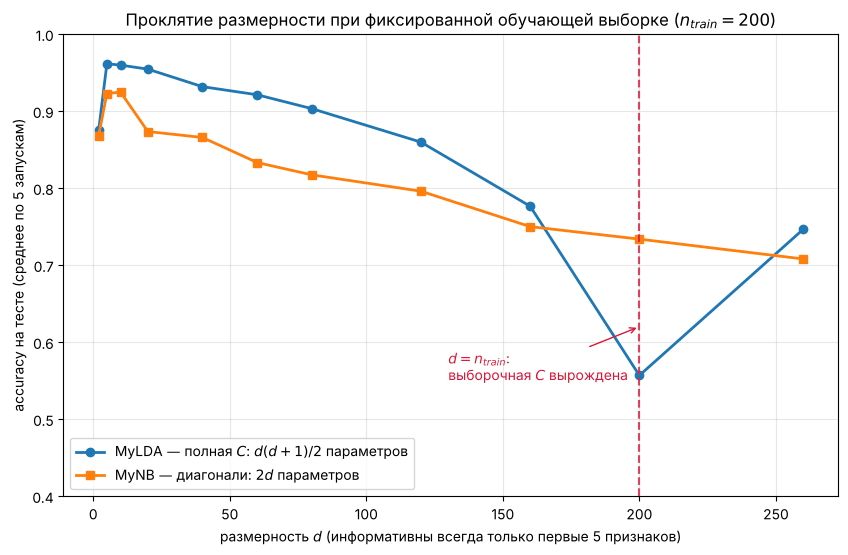

In [28]:
# 6.3 Влияние размерности: обучающая выборка ФИКСИРОВАНА, d растёт
# [правка] такого эксперимента в работе не было, а вопрос о размерности задан в задании.
# Важно: сигнал всегда сосредоточен в первых 5 коррелированных признаках, остальные
# d-5 признаков — чистый шум. Поэтому байесовский предел качества НЕ зависит от d,
# и весь наблюдаемый спад — это цена оценивания параметров, а не изменение задачи.
dims = [2, 5, 10, 20, 40, 60, 80, 120, 160, 200, 260]
N_TRAIN_PER = 100            # всего 200 обучающих объектов
n_repeats = 5
RHO_DIM, DELTA_DIM = 0.7, 0.9

acc_lda, acc_nb = [], []
print(f'{"d":>5} | {"парам. в C":>10} | {"парам. в NB":>11} | {"MyLDA":>6} | {"MyNB":>6}')
print('-' * 54)
for d in dims:
    runs_lda, runs_nb = [], []
    k = min(5, d)
    # общая для классов ковариация: коррелированный блок 5x5 + независимый шум
    C = block_diag(equicorr(k, RHO_DIM), np.eye(d - k)) if d > k else equicorr(k, RHO_DIM)
    mu0 = np.zeros(d)
    mu1 = np.zeros(d)
    mu1[:k] = DELTA_DIM * np.array([1, -1, 1, -1, 1])[:k]
    for rep in range(n_repeats):
        Xd, yd = make_dataset(mu0, C, mu1, C, n=N_TRAIN_PER + 400, seed=2000 + rep)
        X_tr, X_te, y_tr, y_te = train_test_split(
            Xd, yd, train_size=2 * N_TRAIN_PER, random_state=rep, stratify=yd)
        runs_lda.append(accuracy_score(y_te, MyLDA().fit(X_tr, y_tr).predict(X_te)))
        runs_nb.append(accuracy_score(y_te, MyNB().fit(X_tr, y_tr).predict(X_te)))
    acc_lda.append(np.mean(runs_lda))
    acc_nb.append(np.mean(runs_nb))
    print(f'{d:5d} | {d * (d + 1) // 2:10d} | {2 * d:11d} | '
          f'{acc_lda[-1]:6.3f} | {acc_nb[-1]:6.3f}')

plt.figure(figsize=(10, 6))
plt.plot(dims, acc_lda, 'o-', lw=2, label='MyLDA — полная $C$: $d(d+1)/2$ параметров')
plt.plot(dims, acc_nb, 's-', lw=2, label='MyNB — диагонали: $2d$ параметров')
plt.axvline(2 * N_TRAIN_PER, color='crimson', ls='--', alpha=0.8)
plt.annotate('$d = n_{train}$:\nвыборочная $C$ вырождена',
             xy=(2 * N_TRAIN_PER, 0.62), xytext=(130, 0.55),
             color='crimson', fontsize=10,
             arrowprops=dict(arrowstyle='->', color='crimson'))
plt.xlabel('размерность $d$ (информативны всегда только первые 5 признаков)')
plt.ylabel('accuracy на тесте (среднее по 5 запускам)')
plt.title(f'Проклятие размерности при фиксированной обучающей выборке '
          f'($n_{{train}} = {2 * N_TRAIN_PER}$)')
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0.4, 1.0)
plt.show()
